# Notebook 3: RCA Dataset Modeling, Robustness, and Pareto Analysis

## Purpose

This notebook extends the baseline supplementary cementitious material concrete analysis by integrating an RCA-specific dataset. It provides an end-to-end analysis of recycled aggregate concrete compressive strength while addressing the data-quality, validation, feature-redundancy, sustainability, and Pareto-frontier concerns identified during the repository review.

The selected dataset is:

**Awoyera, Paul (2025), “Mechanical Properties of Recycled Aggregate Concrete,” Mendeley Data, Version 1. DOI: `10.17632/2pxdbh6vx7.1`.**

The analysis:

1. Loads and standardizes the RCA dataset.
2. Preserves source-row identifiers for auditing.
3. Applies documented corrections only when supplied in a correction file.
4. Detects and quarantines physically implausible values rather than silently changing them.
5. Audits whether the reported aggregate-cement ratio is consistent with the material quantities.
6. Compares compact, original, and engineered feature sets.
7. Uses group-aware cross-validation for model comparison and hyperparameter tuning.
8. Evaluates the selected model on one untouched grouped hold-out set.
9. performs repeated nested grouped validation to estimate model-development variability.
10. Calculates a simplified emissions proxy under low, central, and high literature scenarios.
11. Generates Pareto candidates using out-of-fold predictions across the full cleaned dataset.
12. Measures whether Pareto candidates remain stable across emissions-factor scenarios.
13. Reports subgroup errors, limitations, and a cautious final synthesis.

## Interpretation limits

- This notebook estimates compressive strength from a small compiled dataset.
- It does not establish causal material effects.
- The sustainability calculation is a simplified emissions proxy, not a complete life-cycle assessment.
- Pareto candidates are nondominated observed mixtures within this dataset, not globally optimized concrete recipes.
- External validation on an independent RCA dataset is still needed for stronger generalization claims.

## 1. Required repository files

Place the RCA dataset in the repository `data/` folder using either the recommended name or the original Mendeley filename:

```text
data/rca_awoyera_2025_mechanical_properties.xlsx
data/RCA for New model.xlsx
```

Optional supporting files:

```text
data/rca_data_corrections.csv
data/rca_sustainability_factor_scenarios.csv
```

The corrections file must contain:

```text
source_row_number,column,corrected_value,reason,source_evidence
```

Corrections are applied only when a documented file is present. Otherwise, physically implausible rows are saved for manual review and excluded from modeling.

In [1]:
# Installs dependencies when running in Google Colab.
# If these packages are already installed, this cell will finish quickly.
import os
import re
import sys
import json
import hashlib
import platform
import subprocess
import warnings
from pathlib import Path

try:
    import openpyxl  # needed for .xlsx files
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "openpyxl"]
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    GridSearchCV,
    cross_validate,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
)
from sklearn.inspection import permutation_importance

# Cleans the output by hiding old code alerts
warnings.filterwarnings("ignore", category=FutureWarning)

# Ensures repeatability
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Referenced multiple times in the code to differentiate outputs and figures
# from other datasets
OUTPUT_PREFIX = "rca"

# Increase for higher resolution images
FIG_DPI = 300

# Number of outer repeated grouped validation splits.
# Ten is suitable for a standard Colab run. Increase for the final frozen run.
# Used in section 12 of the notebook
N_REPEATED_GROUP_SPLITS = int(
    os.environ.get("RCA_NESTED_REPEATS", "10")
)

# Flagged rows are excluded after being saved for manual review.
# No value is silently corrected.
FLAGGED_ROW_POLICY = "exclude"

# Creates data folder for loading the dataset
os.makedirs("data", exist_ok=True)

## 2. Project paths

Repository mode is the default. Google Drive remains available as an optional workflow.

In [2]:
# ============================================================
# Project configuration
# ============================================================
# Use variable if using non-repo directory
# ECO_CONCRETE_DRIVE_BASE = (directory link)
RUN_MODE = os.environ.get(
    "ECO_CONCRETE_RUN_MODE",
    "repo",
).strip().lower()

# Mounts drive and establishes dataset
if RUN_MODE == "drive":
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError(
            "RUN_MODE='drive' requires Google Colab."
        ) from exc

    drive.mount("/content/drive")

    BASE_DIR = Path(
        os.environ.get(
            "ECO_CONCRETE_DRIVE_BASE",
            "/content/drive/MyDrive/Indigo Research Project",
        )
    )

# Repo option makes the notebook runnable from GitHub
# Make sure to add data folder to local notebook files
elif RUN_MODE == "repo":
    cwd = Path.cwd()
    BASE_DIR = cwd.parent if cwd.name == "notebooks" else cwd

else:
    raise ValueError(
        "RUN_MODE must be either 'repo' or 'drive'."
    )

# Output folders
# DATA_DIR from the previous code is defined for referencing
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "figures"
OUT_DIR = BASE_DIR / "outputs"

# Checks and creates missing folders, if applicable
# If all folders exist, code is ignored
# DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Displays set-up details for verification
print("RUN_MODE:", RUN_MODE)
print("BASE_DIR:", BASE_DIR)
print("DATA_DIR:", DATA_DIR)
print("FIG_DIR:", FIG_DIR)
print("OUT_DIR:", OUT_DIR)

RUN_MODE: repo
BASE_DIR: /content
DATA_DIR: /content/data
FIG_DIR: /content/figures
OUT_DIR: /content/outputs


## 3. Load and standardize the selected RCA dataset

The loader accepts `.xlsx`, `.xls`, or `.csv`. When an Excel workbook contains multiple sheets, the sheet with the strongest match to the expected RCA schema is selected.

In [3]:
# Defines citation elements of the uploaded dataset
RCA_DATASET_DOI = "10.17632/2pxdbh6vx7.1"
RCA_DATASET_TITLE = (
    "Mechanical Properties of Recycled Aggregate Concrete"
)
RCA_DATASET_AUTHOR = "Paul Awoyera"
RCA_DATASET_YEAR = "2025"

# Selects dataset off of common names
# Helps differentiate between multiple uploaded datasets
RCA_DATASET_CANDIDATES = [
    "rca_awoyera_2025_mechanical_properties.xlsx",
    "RCA for New model.xlsx",
    "rca_for_new_model.xlsx",
    "mechanical_properties_recycled_aggregate_concrete.xlsx",
    "rca_awoyera_2025_mechanical_properties.csv",
]

# Checks if a valid candidate exists; if not, print error message
for filename in RCA_DATASET_CANDIDATES:
    candidate = DATA_DIR / filename
    if candidate.exists():
        rca_path = candidate
        break
else:
    available = sorted(path.name for path in DATA_DIR.glob("*"))

    message = [
        "Could not find the selected RCA dataset in data/.",
        "",
        (
            f"Dataset: {RCA_DATASET_AUTHOR} ({RCA_DATASET_YEAR}), "
            f"'{RCA_DATASET_TITLE}', DOI {RCA_DATASET_DOI}."
        ),
        (
            "Save it as "
            "data/rca_awoyera_2025_mechanical_properties.xlsx "
            "or keep the original filename 'RCA for New model.xlsx'."
        ),
        "",
        "Current files in data/:",
        *[f"- {item}" for item in available],
    ]

    raise FileNotFoundError("\n".join(message))

# If dataset does exist, print the selected dataset
# Use this as a final check for the correct dataset
print("RCA dataset file:", rca_path)

RCA dataset file: /content/data/rca_awoyera_2025_mechanical_properties.xlsx


In [4]:
# Normalizes the dataset columns to improve code reliability
# Can improve speed for larger datasets
def normalize_col(name):
    name = str(name).strip().lower()
    name = name.replace("²", "2").replace("³", "3")
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return re.sub(r"_+", "_", name).strip("_")

# Specifically searches for exact target and feature columns
# Returns the normalized columns before continuing
def canonical_name(name):
    normalized = normalize_col(name)

    if normalized in {
        "w_c",
        "wc",
        "w_c_ratio",
        "water_cement_ratio",
        "water_to_cement_ratio",
    }:
        return "water_cement_ratio"

    if (
        "water" in normalized
        and "cement" in normalized
        and "ratio" in normalized
    ):
        return "water_cement_ratio"

    if normalized in {
        "a_c",
        "ac",
        "aggregate_cement_ratio",
        "aggregate_to_cement_ratio",
    }:
        return "aggregate_cement_ratio"

    if (
        "aggregate" in normalized
        and "cement" in normalized
        and "ratio" in normalized
    ):
        return "aggregate_cement_ratio"

    if normalized in {
        "water",
        "water_kg_m3",
        "water_kg_m_3",
    }:
        return "water"

    if normalized in {
        "cement",
        "cement_kg_m3",
        "cement_kg_m_3",
    }:
        return "cement"

    if normalized in {
        "nfa",
        "natural_fine_aggregate",
        "natural_fine_aggregate_kg_m3",
    }:
        return "natural_fine_aggregate"

    if (
        "natural" in normalized
        and "fine" in normalized
        and "aggregate" in normalized
    ):
        return "natural_fine_aggregate"

    if normalized in {
        "nca",
        "natural_coarse_aggregate",
        "natural_coarse_aggregate_kg_m3",
    }:
        return "natural_coarse_aggregate"

    if (
        "natural" in normalized
        and "coarse" in normalized
        and "aggregate" in normalized
    ):
        return "natural_coarse_aggregate"

    if normalized in {
        "rca",
        "recycled_coarse_aggregate",
        "recycled_coarse_aggregate_kg_m3",
    }:
        return "recycled_coarse_aggregate"

    if (
        "recycled" in normalized
        and "coarse" in normalized
        and "aggregate" in normalized
    ):
        return "recycled_coarse_aggregate"

    if normalized in {
        "rfa",
        "recycled_fine_aggregate",
        "recycled_fine_aggregate_kg_m3",
    }:
        return "recycled_fine_aggregate"

    if (
        "recycled" in normalized
        and "fine" in normalized
        and "aggregate" in normalized
    ):
        return "recycled_fine_aggregate"

    if "compressive" in normalized and "strength" in normalized:
        return "compressive_strength_mpa"

    if (
        "split" in normalized
        and "tensile" in normalized
        and "strength" in normalized
    ):
        return "split_tensile_strength_mpa"

    if "tensile" in normalized and "strength" in normalized:
        return "split_tensile_strength_mpa"

    if "flexural" in normalized and "strength" in normalized:
        return "flexural_strength_mpa"

    if "modulus" in normalized and "elastic" in normalized:
        return "modulus_of_elasticity_mpa"

    return normalized

# Removes identical or redundant columns from dataset
# Prevents calculation errors and cleans up the dataset
def collapse_duplicate_columns(frame):
    if not frame.columns.duplicated().any():
        return frame
    combined = pd.DataFrame(index=frame.index)
    for column in pd.unique(frame.columns):
        subset = frame.loc[:, frame.columns == column]
        combined[column] = subset.bfill(axis=1).iloc[:, 0]
    return combined

# Checks the dataset's format to the code's expectations
# Prevents schema drift or structure change
def schema_match_score(frame):
    temporary = frame.copy()
    temporary.columns = [
        canonical_name(column)
        for column in temporary.columns
    ]

    expected = {
        "water_cement_ratio",
        "aggregate_cement_ratio",
        "water",
        "cement",
        "natural_fine_aggregate",
        "natural_coarse_aggregate",
        "recycled_coarse_aggregate",
        "recycled_fine_aggregate",
        "compressive_strength_mpa",
    }

    return len(set(temporary.columns).intersection(expected))

# Checks the file type and selects the best sheet after cleaning the data
# Puts into pandas DataFrame
def load_rca_table(path):
    suffix = path.suffix.lower()
    if suffix == ".csv":
        raw = pd.read_csv(path)
        selected_sheet = "csv"
    elif suffix in {".xlsx", ".xls"}:
        workbook = pd.ExcelFile(path)
        sheet_options = []
        for sheet_name in workbook.sheet_names:
            sheet = pd.read_excel(
                path,
                sheet_name=sheet_name,
            )
            sheet = (
                sheet.dropna(how="all")
                .dropna(axis=1, how="all")
            )
            if len(sheet) > 0:
                sheet_options.append(
                    (
                        sheet_name,
                        schema_match_score(sheet),
                        sheet,
                    )
)
        if not sheet_options:
            raise ValueError("The Excel file contains no nonempty sheets.")
        selected_sheet, score, raw = max(sheet_options, key=lambda item: item[1],)
        print(f"Selected sheet: {selected_sheet}; "f"schema score: {score}")
    else:
        raise ValueError(f"Unsupported file type: {suffix}")

    # Cleans pandas DataFrame before returning it
    raw = raw.copy()
    # Preserve the approximate spreadsheet row number for auditing.
    raw["source_row_number"] = np.arange(2, len(raw) + 2)
    raw.columns = [canonical_name(column) for column in raw.columns ]
    raw = collapse_duplicate_columns(raw)
    raw = raw.dropna(how="all")
    raw["source_file"] = path.name
    raw["source_sheet"] = selected_sheet
    return raw

# Displays current cleaned data table for verification
raw_df = load_rca_table(rca_path)
print("Raw shape:", raw_df.shape)
display(raw_df.head())

Selected sheet: Sheet1; schema score: 9
Raw shape: (112, 15)


,water_cement_ratio,aggregate_cement_ratio,water,cement,natural_fine_aggregate,natural_coarse_aggregate,recycled_coarse_aggregate,recycled_fine_aggregate,compressive_strength_mpa,split_tensile_strength_mpa,flexural_strength_mpa,modulus_of_elasticity_mpa,source_row_number,source_file,source_sheet
0,0.4,4.25,120.0,300.0,763.0,1366.000000,340.000000,214.333333,34.8,4.0,4.2,33288.0,2,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1
1,0.4,4.25,120.0,300.0,763.0,1025.000000,290.000000,549.403333,33.2,3.8,4.1,31684.0,3,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1
2,0.4,4.25,120.0,300.0,763.0,683.000000,570.000000,202.450000,32.1,3.5,4.0,28510.0,4,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1
3,0.4,4.25,120.0,300.0,763.0,823.333333,1150.000000,198.403333,29.3,3.0,3.9,22215.0,5,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1
4,0.4,4.25,140.0,350.0,728.0,1304.000000,361.666667,214.333333,41.2,4.3,4.5,37800.0,6,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1


**Result Interpretation:** The code states that the number of rows in the original dataset is 112, and the number of columns is 15. This is before any rows are removed.

## 4. Apply documented corrections, then audit data quality

The current dataset previously produced a recycled coarse aggregate value of `11,027`, which is physically implausible under a `kg/m³` interpretation. This notebook does not guess that the value should be `1,102.7`. Instead, it:

1. Applies a correction only when a documented correction file is supplied.
2. Saves every flagged row for manual review.
3. Suggests a possible decimal-shift review when division by 10 would place the value within the plausible range.
4. Excludes unresolved flagged rows from modeling.

In [5]:
# Defines columns into categories
# Uses listed names as machine learning inputs
TARGET_COL = "compressive_strength_mpa"

ORIGINAL_FEATURES = [
    "water_cement_ratio",
    "aggregate_cement_ratio",
    "water",
    "cement",
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_coarse_aggregate",
    "recycled_fine_aggregate",
]

OPTIONAL_OUTPUTS = [
    "split_tensile_strength_mpa",
    "flexural_strength_mpa",
    "modulus_of_elasticity_mpa",
]

# Verifies that all columns are present in dataset before continuing
required_columns = ORIGINAL_FEATURES + [TARGET_COL]

missing_required = [
    column
    for column in required_columns
    if column not in raw_df.columns
]

if missing_required:
    raise KeyError(
        "Missing required columns after normalization: "
        f"{missing_required}. "
        f"Available columns: {raw_df.columns.tolist()}"
    )

# Retains additional columns not required for concrete compressive strength predictions
available_optional_outputs = [
    column
    for column in OPTIONAL_OUTPUTS
    if column in raw_df.columns
]

model_df = raw_df[
    required_columns
    + available_optional_outputs
    + [
        "source_row_number",
        "source_file",
        "source_sheet",
    ]
].copy()

# Converts and/or coerces values into numerics
for column in required_columns + available_optional_outputs:
    model_df[column] = pd.to_numeric(
        model_df[column],
        errors="coerce",
    )

# ------------------------------------------------------------
# Optional documented corrections
# ------------------------------------------------------------
# Ensure the file is correctly named for corrections to be implemented
# Use after manual review of the dataset
corrections_path = DATA_DIR / "rca_data_corrections.csv"
correction_log = []

# Checks if CSV exists, then confirms all the required columns exist
# If they don't, then raise an error message
# Same process is done with rows
if corrections_path.exists():
    corrections_df = pd.read_csv(corrections_path)

    required_correction_columns = {
        "source_row_number",
        "column",
        "corrected_value",
        "reason",
        "source_evidence",
    }

    missing_correction_columns = (
        required_correction_columns
        - set(corrections_df.columns)
    )

    if missing_correction_columns:
        raise ValueError(
            "Correction file is missing columns: "
            f"{sorted(missing_correction_columns)}"
        )

    for _, correction in corrections_df.iterrows():
        row_number = int(correction["source_row_number"])
        column = str(correction["column"]).strip()

        if column not in required_columns:
            raise ValueError(
                f"Correction refers to unknown column: {column}"
            )

        row_mask = (
            model_df["source_row_number"]
            == row_number
        )

        if row_mask.sum() != 1:
            raise ValueError(
                "Correction row could not be uniquely matched: "
                f"source_row_number={row_number}"
            )

        original_value = model_df.loc[
            row_mask,
            column,
        ].iloc[0]

        corrected_value = float(
            correction["corrected_value"]
        )

        model_df.loc[
            row_mask,
            column,
        ] = corrected_value

        correction_log.append(
            {
                "source_row_number": row_number,
                "column": column,
                "original_value": original_value,
                "corrected_value": corrected_value,
                "reason": correction["reason"],
                "source_evidence": correction[
                    "source_evidence"
                ],
            }
        )

# Saves and applies the corrections to the current dataset
# Makes recording corrections simpler during review
correction_log_df = pd.DataFrame(correction_log)
correction_log_path = (
    OUT_DIR / "rca_documented_correction_log.csv"
)
correction_log_df.to_csv(
    correction_log_path,
    index=False,
)

print(
    "Documented corrections applied:",
    len(correction_log_df),
)
print("Saved:", correction_log_path)

Documented corrections applied: 1
Saved: /content/outputs/rca_documented_correction_log.csv


**Result Interpretation:** One correction is applied to the original dataset. A total of 112 rows and 15 columns still exist, but have been edited based on manual review of the data.

In [6]:
# ============================================================
# Missing, finite, and physically plausible value audit setup
# ============================================================
# Code notifies the user of missing values or incomplete rows, then deletes them
# Important for manual fixes and helps run the code regardless of errors
print(
    "Missing or nonnumeric required values before filtering:"
)
display(
    model_df[required_columns]
    .isna()
    .sum()
    .to_frame("missing_count")
)

model_df["total_aggregate_raw"] = (
    model_df["natural_fine_aggregate"]
    + model_df["natural_coarse_aggregate"]
    + model_df["recycled_fine_aggregate"]
    + model_df["recycled_coarse_aggregate"]
)

# ============================================================
# Nonnegative and positive value check
# ============================================================
# Checks for impossible values in the dataset
# Removes them if they exist
nonnegative_cols = ORIGINAL_FEATURES
positive_cols = ["water_cement_ratio", "aggregate_cement_ratio", "water", "cement", TARGET_COL]
invalid_rows = (
    (model_df[nonnegative_cols] < 0).any(axis=1)
    | (model_df[positive_cols] <= 0).any(axis=1)
    | (~np.isfinite(model_df[required_columns]).all(axis=1))
)
print("Rows removed for impossible values:", int(invalid_rows.sum()))
model_df = model_df.loc[~invalid_rows].copy()

# Checks values for magnitude
max_rca_index = model_df["recycled_coarse_aggregate"].idxmax()
display(model_df.loc[[max_rca_index]])

# ============================================================
# Plausible and missing values check
# ============================================================
# Code defines the plausible ranges for each feature
# Ranges can be edited for more/less variation between mixtures
PLAUSIBILITY_LIMITS = {
    "water_cement_ratio": (0.20, 1.20),
    "aggregate_cement_ratio": (0.50, 12.00),
    "water": (50.0, 500.0),
    "cement": (100.0, 1000.0),
    "natural_fine_aggregate": (0.0, 2500.0),
    "natural_coarse_aggregate": (0.0, 2500.0),
    "recycled_fine_aggregate": (0.0, 2500.0),
    "recycled_coarse_aggregate": (0.0, 2500.0),
    "compressive_strength_mpa": (1.0, 150.0),
    "total_aggregate_raw": (300.0, 4000.0),
}

# Checks if the column being audited falls outside its defined range
# If so, the column is classified as "invalid"
audit_df = model_df.copy()
audit_df["quality_flags"] = ""

for column, (lower, upper) in PLAUSIBILITY_LIMITS.items():
    invalid = (
        audit_df[column].isna()
        | ~np.isfinite(audit_df[column])
        | (audit_df[column] < lower)
        | (audit_df[column] > upper)
    )

    audit_df.loc[
        invalid,
        "quality_flags",
    ] += (
        f"{column}_outside_"
        f"[{lower},{upper}];"
    )

# Initializes an empty list for inputting invalid feature columns
audit_df["suggested_manual_review"] = ""

# Code checks aggregate values by applying plausability ranges
aggregate_columns = [
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_fine_aggregate",
    "recycled_coarse_aggregate",
]

for column in aggregate_columns:
    decimal_shift_candidate = (
        (audit_df[column] > 2500.0)
        & (audit_df[column] / 10.0 <= 2500.0)
    )

    audit_df.loc[
        decimal_shift_candidate,
        "suggested_manual_review",
    ] += (
        f"Check whether {column} has a misplaced decimal; "
        f"candidate value is current_value/10;"
    )

# Separates flagged rows and saves to a CSV for manual review
flagged_rows = audit_df[
    audit_df["quality_flags"].str.len() > 0
].copy()

flagged_path = (
    OUT_DIR / "rca_flagged_rows_for_manual_review.csv"
)
flagged_rows.to_csv(
    flagged_path,
    index=False,
)

# Shows and prints flagged rows if they exist
print("Flagged rows:", len(flagged_rows))
print("Saved:", flagged_path)

if len(flagged_rows) > 0:
    display(
        flagged_rows[
            [
                "source_row_number",
                *required_columns,
                "total_aggregate_raw",
                "quality_flags",
                "suggested_manual_review",
            ]
        ]
    )

# Variable is set at the beginning of the notebook
# The present notebook runs FLAGGED_ROW_POLICY = "exclude" and saves the
# excluded rows for manual review
if FLAGGED_ROW_POLICY == "exclude":
    model_df = audit_df[
        audit_df["quality_flags"].str.len() == 0
    ].copy()

elif FLAGGED_ROW_POLICY == "error":
    if len(flagged_rows) > 0:
        raise ValueError(
            "Physically implausible rows were detected. "
            "Review the saved audit before continuing."
        )
    model_df = audit_df.copy()

else:
    raise ValueError(
        "FLAGGED_ROW_POLICY must be 'exclude' or 'error'."
    )

# Checks the CSV for missing values in rows
# If values are missing, remove the row from the dataset
rows_before_missing_filter = len(model_df)

model_df = model_df.dropna(
    subset=required_columns
).copy()

print(
    "Rows removed for missing required values:",
    rows_before_missing_filter - len(model_df),
)

# Checks the CSV for exact duplicate rows
# If so, drop all duplicates beside the first instance and reset the DataFrame index
exact_duplicate_count = int(
    model_df.duplicated(
        subset=required_columns,
        keep=False,
    ).sum()
)

print(
    "Rows involved in exact duplicate feature/target records:",
    exact_duplicate_count,
)

model_df = (
    model_df
    .drop_duplicates(
        subset=required_columns,
    )
    .reset_index(drop=True)
)

# Displays the prepared rows for the user
print("Prepared rows after audit:", len(model_df))

Missing or nonnumeric required values before filtering:


,missing_count
water_cement_ratio,0
aggregate_cement_ratio,0
water,0
cement,0
natural_fine_aggregate,0
natural_coarse_aggregate,0
recycled_coarse_aggregate,0
recycled_fine_aggregate,0
compressive_strength_mpa,0


Rows removed for impossible values: 0


,water_cement_ratio,aggregate_cement_ratio,water,cement,natural_fine_aggregate,natural_coarse_aggregate,recycled_coarse_aggregate,recycled_fine_aggregate,compressive_strength_mpa,split_tensile_strength_mpa,flexural_strength_mpa,modulus_of_elasticity_mpa,source_row_number,source_file,source_sheet,total_aggregate_raw
46,0.49,4.25,211.0,398.0,614.0,278.333333,1193.0,204.736667,44.26,3.651791,5.07,40800.0,48,rca_awoyera_2025_mechanical_properties.xlsx,Sheet1,2290.07


Flagged rows: 0
Saved: /content/outputs/rca_flagged_rows_for_manual_review.csv
Rows removed for missing required values: 0
Rows involved in exact duplicate feature/target records: 8
Prepared rows after audit: 105


**Result Interpretation:** With 8 duplicate records and 112 original rows, the final number of prepared rows indicate that 7 duplicate rows have been removed from the dataset. Note that the first instance of a row is counted as a duplicate. Since the amount of rows is small, the grouped split changes a very small number of repeated mixtures. This information will be expanded upon in section 12 of the present code.

## 5. Audit the aggregate-cement ratio and units

The reported aggregate-cement ratio is compared against several calculations derived from the material columns. The notebook uses the reported ratio as a model feature only when at least 80% of rows agree with the all-aggregate calculation within a tolerance of `±0.25` or 10%.

Failure of this check does not prove that the source column is wrong. It means the column definition or units are not sufficiently clear for use as a verified physical predictor.

In [7]:
# Defines and creates the interpretable RCA variables
# Equations are listed in the code for understanding where each value comes from
model_df["total_natural_aggregate"] = (
    model_df["natural_fine_aggregate"]
    + model_df["natural_coarse_aggregate"]
)

model_df["total_recycled_aggregate"] = (
    model_df["recycled_fine_aggregate"]
    + model_df["recycled_coarse_aggregate"]
)

model_df["total_fine_aggregate"] = (
    model_df["natural_fine_aggregate"]
    + model_df["recycled_fine_aggregate"]
)

model_df["total_coarse_aggregate"] = (
    model_df["natural_coarse_aggregate"]
    + model_df["recycled_coarse_aggregate"]
)

model_df["total_aggregate"] = (
    model_df["total_fine_aggregate"]
    + model_df["total_coarse_aggregate"]
)

model_df["aggregate_ratio_from_all_materials"] = (
    model_df["total_aggregate"]
    / model_df["cement"]
)

model_df["aggregate_ratio_from_natural_only"] = (
    model_df["total_natural_aggregate"]
    / model_df["cement"]
)

model_df["aggregate_ratio_from_coarse_only"] = (
    model_df["total_coarse_aggregate"]
    / model_df["cement"]
)

# Creates a new DataFrame to compare specific aggregate-cement ratio columns
ratio_audit = pd.DataFrame(
    {
        "reported_aggregate_cement_ratio": (
            model_df["aggregate_cement_ratio"]
        ),
        "ratio_from_all_aggregate_columns": (
            model_df[
                "aggregate_ratio_from_all_materials"
            ]
        ),
        "ratio_from_natural_aggregate_only": (
            model_df[
                "aggregate_ratio_from_natural_only"
            ]
        ),
        "ratio_from_coarse_aggregate_only": (
            model_df[
                "aggregate_ratio_from_coarse_only"
            ]
        ),
        "source_row_number": (
            model_df["source_row_number"]
        ),
    }
)

# Takes the absolute difference by subtracting two ratios
# Then compares the values of the two ratios
# Allowed difference is defined by rtol and atol
ratio_audit[
    "all_materials_absolute_difference"
] = (
    ratio_audit[
        "reported_aggregate_cement_ratio"
    ]
    - ratio_audit[
        "ratio_from_all_aggregate_columns"
    ]
).abs()

ratio_close = np.isclose(
    ratio_audit[
        "reported_aggregate_cement_ratio"
    ],
    ratio_audit[
        "ratio_from_all_aggregate_columns"
    ],
    rtol=0.10,
    atol=0.25,
)

# Calculates the median absolute difference of the aggregate columns
aggregate_ratio_consistency_rate = float(
    ratio_close.mean()
)

# Checks if at least 80% of the columns fall within the set relative or absolute tolerance
# See variables rtol (10%) and atol (±0.25)
aggregate_ratio_verified = bool(
    aggregate_ratio_consistency_rate >= 0.80
)

# Saves audit CSV for proof of data quality
ratio_audit_path = (
    OUT_DIR
    / "rca_aggregate_cement_ratio_audit.csv"
)

ratio_audit.to_csv(
    ratio_audit_path,
    index=False,
)

# Prints and creates a summary defining if the tested columns are sufficiently
# clear as a verified physical predictor
print("Saved:", ratio_audit_path)
print(
    "Aggregate-cement ratio consistency rate:",
    round(aggregate_ratio_consistency_rate, 3),
)
print(
    "Use reported aggregate-cement ratio as a verified feature:",
    aggregate_ratio_verified,
)

ratio_summary = pd.DataFrame(
    [
        {
            "comparison": "reported_vs_all_aggregate_columns",
            "median_absolute_difference": (
                ratio_audit[
                    "all_materials_absolute_difference"
                ].median()
            ),
            "consistency_rate_within_tolerance": (
                aggregate_ratio_consistency_rate
            ),
            "verified_for_modeling": (
                aggregate_ratio_verified
            ),
        }
    ]
)

display(ratio_summary)

Saved: /content/outputs/rca_aggregate_cement_ratio_audit.csv
Aggregate-cement ratio consistency rate: 0.162
Use reported aggregate-cement ratio as a verified feature: False


,comparison,median_absolute_difference,consistency_rate_within_tolerance,verified_for_modeling
0,reported_vs_all_aggregate_columns,1.976804,0.161905,False


**Result Interpretation:** The consistency rate between reported and calculated aggregate cement-ratios is low (21.4%). This indicates that the sensitivity analysis, which uses calculated aggregate values, is not fully accurate, and should be considered a preliminary sensitivity analysis (refer to section 15-16).

## 6. RCA-specific feature engineering

The compact feature set avoids placing several deterministic versions of the same quantity into one model. The full engineered set is retained only for an ablation comparison.

In [8]:
# Defines a tolerance value
# Used for calculations that result in excessive/repeating decimals
EPS = 1e-12

# Defines and creates additional RCA variables w/ equations listed in the code
model_df["recycled_aggregate_fraction"] = (
    model_df["total_recycled_aggregate"]
    / (model_df["total_aggregate"] + EPS)
)

model_df["recycled_coarse_fraction"] = (
    model_df["recycled_coarse_aggregate"]
    / (
        model_df["total_coarse_aggregate"]
        + EPS
    )
)

model_df["recycled_fine_fraction"] = (
    model_df["recycled_fine_aggregate"]
    / (
        model_df["total_fine_aggregate"]
        + EPS
    )
)

model_df[
    "water_to_cement_from_quantities"
] = (
    model_df["water"]
    / (model_df["cement"] + EPS)
)

# Puts original features into a separate category for easy reference
# Important for differentiating between original features from the dataset and calculated features
base_verified_features = [
    "water_cement_ratio",
    "water",
    "cement",
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_coarse_aggregate",
    "recycled_fine_aggregate",
]

if aggregate_ratio_verified:
    base_verified_features.insert(
        1,
        "aggregate_cement_ratio",
    )

# Defines every feature into a category for output reference
# Useful documentation for anyone unfamiliar with the data
FEATURE_SETS = {
    "verified_original": base_verified_features,

    "compact_physical": [
        "water_cement_ratio",
        "cement",
        "total_fine_aggregate",
        "total_coarse_aggregate",
        "recycled_fine_fraction",
        "recycled_coarse_fraction",
    ],

    "full_engineered": list(
        dict.fromkeys(
            base_verified_features
            + [
                "total_natural_aggregate",
                "total_recycled_aggregate",
                "total_fine_aggregate",
                "total_coarse_aggregate",
                "total_aggregate",
                "recycled_aggregate_fraction",
                "recycled_coarse_fraction",
                "recycled_fine_fraction",
                "water_to_cement_from_quantities",
            ]
        )
    ),
}

# Prepares a location for the final modeling table in the output folder
prepared_path = (
    OUT_DIR / "prepared_rca_modeling_table_rca.csv"
)

model_df.to_csv(
    prepared_path,
    index=False,
)

# Defines the format for the RCA modeling table
# Converts table into the pandas DataFrame before saving for publication
feature_set_rows = []

for name, features in FEATURE_SETS.items():
    for feature in features:
        feature_set_rows.append(
            {
                "feature_set": name,
                "feature": feature,
            }
        )

feature_set_df = pd.DataFrame(
    feature_set_rows
)

feature_set_path = (
    OUT_DIR / "rca_feature_sets_rca.csv"
)

feature_set_df.to_csv(
    feature_set_path,
    index=False,
)

# Prints all code results for user confirmation
print("Saved:", prepared_path)
print("Saved:", feature_set_path)

for name, features in FEATURE_SETS.items():
    print(name, ":", features)

Saved: /content/outputs/prepared_rca_modeling_table_rca.csv
Saved: /content/outputs/rca_feature_sets_rca.csv
verified_original : ['water_cement_ratio', 'water', 'cement', 'natural_fine_aggregate', 'natural_coarse_aggregate', 'recycled_coarse_aggregate', 'recycled_fine_aggregate']
compact_physical : ['water_cement_ratio', 'cement', 'total_fine_aggregate', 'total_coarse_aggregate', 'recycled_fine_fraction', 'recycled_coarse_fraction']
full_engineered : ['water_cement_ratio', 'water', 'cement', 'natural_fine_aggregate', 'natural_coarse_aggregate', 'recycled_coarse_aggregate', 'recycled_fine_aggregate', 'total_natural_aggregate', 'total_recycled_aggregate', 'total_fine_aggregate', 'total_coarse_aggregate', 'total_aggregate', 'recycled_aggregate_fraction', 'recycled_coarse_fraction', 'recycled_fine_fraction', 'water_to_cement_from_quantities']


## 7. Exploratory data analysis

These figures describe the cleaned dataset. Correlations are exploratory and are not treated as causal effects or model importance.

Saved: /content/outputs/rca_summary_statistics_rca.csv


,count,mean,std,min,25%,50%,75%,max
water_cement_ratio,105.0,0.468090,0.069447,0.340000,0.440000,0.468090,0.500000,0.680000
water,105.0,183.311087,28.807805,120.000000,165.000000,183.311087,204.600000,265.000000
cement,105.0,389.557692,52.117439,300.000000,350.000000,400.000000,425.000000,488.000000
natural_fine_aggregate,105.0,665.861043,108.074538,344.020000,614.000000,678.000000,711.000000,1115.320000
natural_coarse_aggregate,105.0,833.757792,282.287994,119.000000,652.000000,823.333333,1090.000000,1366.000000
recycled_coarse_aggregate,105.0,748.215508,328.459964,119.000000,460.000000,835.000000,1058.560000,1193.000000
recycled_fine_aggregate,105.0,277.220281,151.964843,69.881538,199.646667,206.790000,339.520000,728.000000
total_recycled_aggregate,105.0,1025.435789,382.500937,325.790000,708.371026,1146.210000,1288.403333,1820.000000
recycled_aggregate_fraction,105.0,0.399682,0.110395,0.161780,0.325460,0.432744,0.488178,0.647368
compressive_strength_mpa,105.0,43.342885,12.461527,14.800000,34.600000,42.030000,50.000000,80.500000


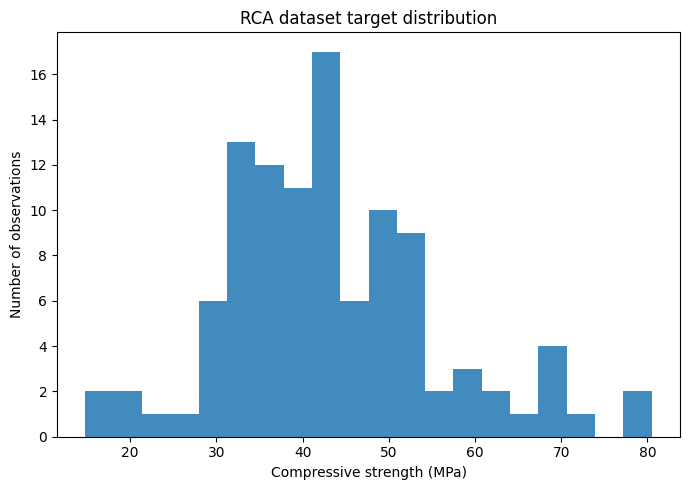

Saved: /content/figures/target_distribution_rca.png


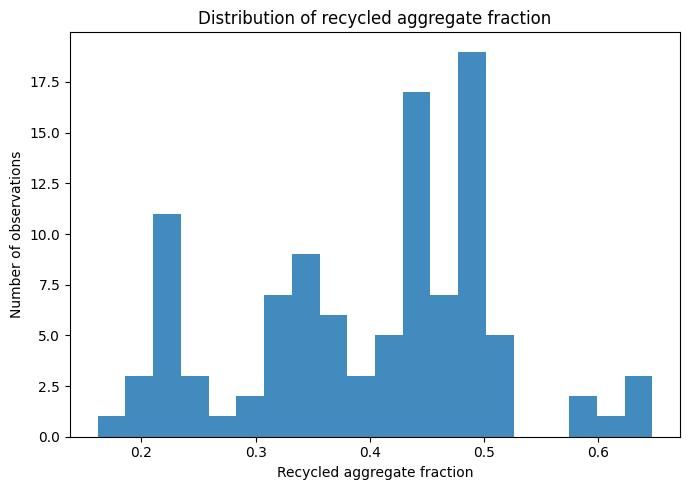

Saved: /content/figures/recycled_aggregate_fraction_distribution_rca.png


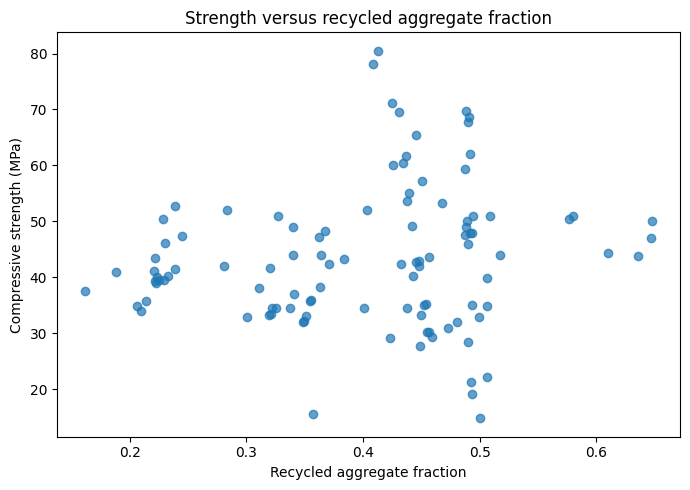

Saved: /content/figures/strength_vs_recycled_fraction_rca.png


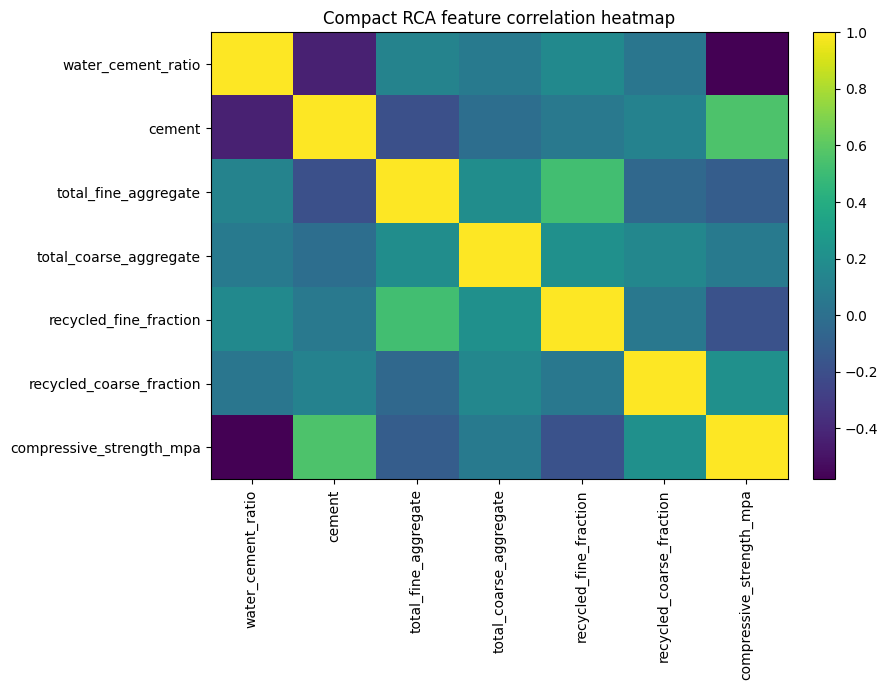

Saved: /content/figures/correlation_heatmap_rca.png


In [9]:
# Creates statistics summary for each feature before creating publication-ready figures
# Acts as a way to check for reasonable ranges and distributions in the data
summary_columns = list(
    dict.fromkeys(
        [
            *base_verified_features,
            "total_recycled_aggregate",
            "recycled_aggregate_fraction",
            TARGET_COL,
        ]
    )
)

summary_stats = (
    model_df[summary_columns]
    .describe()
    .T
)

summary_path = (
    OUT_DIR / "rca_summary_statistics_rca.csv"
)

summary_stats.to_csv(summary_path)

print("Saved:", summary_path)
display(summary_stats)
# ============================================================
# Target distribution graphs
    # Histogram graph shows how the variable varies and shows the mean/median
    # Can be used to improve clustering around a specific value
    # Applies to both the compressive strength and recycled aggregate fraction histograms
# ============================================================
# Concrete compressive strength distribution
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(
    model_df[TARGET_COL],
    bins=20,
    alpha=0.85,
)

ax.set_xlabel(
    "Compressive strength (MPa)"
)
ax.set_ylabel(
    "Number of observations"
)
ax.set_title(
    "RCA dataset target distribution"
)

fig.tight_layout()

fig_path = (
    FIG_DIR / "target_distribution_rca.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

# Recycled aggregate (RA) fraction distribution
# Note that this variable refers to the percentage of RA that makes up the total aggregates
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(
    model_df["recycled_aggregate_fraction"],
    bins=20,
    alpha=0.85
)

ax.set_xlabel(
    "Recycled aggregate fraction"
)

ax.set_ylabel(
    "Number of observations"
)

ax.set_title(
    "Distribution of recycled aggregate fraction"
)

fig.tight_layout()

fig_path = (
    FIG_DIR / f"recycled_aggregate_fraction_distribution_{OUTPUT_PREFIX}.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fig_path)
# ============================================================
# Scatterplot graph
    # Compares concrete compressive strength to recycled aggregate fraction
    # Analyzes how compressive strength variess as RA is integrated
# ============================================================
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    model_df[
        "recycled_aggregate_fraction"
    ],
    model_df[TARGET_COL],
    alpha=0.70,
)

ax.set_xlabel(
    "Recycled aggregate fraction"
)
ax.set_ylabel(
    "Compressive strength (MPa)"
)
ax.set_title(
    "Strength versus recycled aggregate fraction"
)

fig.tight_layout()

fig_path = (
    FIG_DIR
    / "strength_vs_recycled_fraction_rca.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

corr_columns = list(
    dict.fromkeys(
        [
            *FEATURE_SETS["compact_physical"],
            TARGET_COL,
        ]
    )
)

corr = model_df[
    corr_columns
].corr(numeric_only=True)
# ============================================================
# Correlation heatmap
    # Correlation heatmap represents the relationship between materials
    # Yellow is positive correlation (increases together)
    # Purple is negative correlation (decreases together)
    # Graphical representation of feature improtance
# ============================================================
fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    corr.values,
    aspect="auto",
)

ax.set_xticks(
    np.arange(len(corr.columns))
)
ax.set_yticks(
    np.arange(len(corr.index))
)

ax.set_xticklabels(
    corr.columns,
    rotation=90,
)

ax.set_yticklabels(
    corr.index,
)

ax.set_title(
    "Compact RCA feature correlation heatmap"
)

fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04,
)

fig.tight_layout()

fig_path = (
    FIG_DIR / "correlation_heatmap_rca.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

**Target Distribution Histogram:** The target distribution graph shows a heavy amount of clustering between 30-50 MPa. This communicates that the trained models will most likely be more accurate within these compressive strength ranges when predicting mixture strength. Additionally, it shows that there are an insufficient amount of mixtures in the dataset for low and high strength mixtures.

**Recycled Aggregate Fraction Distribution Histogram:** Mixtures with 40-50% recycled aggregate replacement seem to be the most prevalent, alongside a noticiable spike near 20% recycled aggregate replacement. This communicates that the trained models will most likely be more accurate within these recycled aggregate ranges when creating predictions. It also demonstrates that mixtures with a high recycled aggregate content will most likely not be accurately predicted by models trained on the present dataset.

**Strength vs. Recycled Aggregate Fraction Scatterplot:** The scatterplot shows a similar result to the recycled aggregate and target distribution histograms, with a high frequency of mixtures between 30-50 MPa and 40-50% recycled aggregate replacement. Other ranges that do not contain data, such as between 60-80 MPa and 0-40% recycled aggregate replacement, indicate areas where a trained model would become less accurate.

**Correlation Heatmap:** The purpose of this graph is to analyze the exploratory relationships between variables in the present dataset. Notable relationships include the positive correlation between cement and compressive strength, which is present in the UCI dataset in previous notebooks. A negative correlation can be seen between compressive strength and water-cement ratio, indicating its importance in predicting concrete compressive strength. However, it only provides exploratory context for the present data and should not be interpreted as causal evidence or as a replacement for model-based feature importance.

## 8. Define mixture groups and the primary grouped hold-out split

Rows with the same original mixture inputs are assigned to the same group. This prevents the same mixture design from appearing in both training and evaluation subsets.

In [10]:
GROUP_COLUMNS = [
    "water_cement_ratio",
    "water",
    "cement",
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_coarse_aggregate",
    "recycled_fine_aggregate",
]

# Checks if the aggregate ratio is verified before adding it as a column
# Ensures feature is accurate before using it to train the machine learning models
if aggregate_ratio_verified:
    GROUP_COLUMNS.insert(
        1,
        "aggregate_cement_ratio",
    )

# Assigns a unique ID to every mixture to call and differentiate between dataset rows
mix_groups = pd.util.hash_pandas_object(
    model_df[GROUP_COLUMNS].round(8),
    index=False,
).astype(str)

# Prints the number of mixtures and any repeated rows
print(
    "Rows:",
    len(model_df),
)
print(
    "Unique mixture groups:",
    mix_groups.nunique(),
)
print(
    "Repeated-group rows:",
    int(mix_groups.duplicated(keep=False).sum()),
)

all_indices = np.arange(len(model_df))

# Creates a group shuffle split object
# Prevents test data memorization by only allowing a mixture to appear in either
# the test set or the train set
# 20% of the rows go into the test set
primary_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

# Runs the group shuffle split
train_idx, test_idx = next(
    primary_splitter.split(
        all_indices,
        model_df[TARGET_COL],
        groups=mix_groups,
    )
)

# Saves the split
groups_train = mix_groups.iloc[train_idx]
groups_test = mix_groups.iloc[test_idx]

# Checks that a mixture appears in only the test or train set
if set(groups_train).intersection(set(groups_test)):
    raise RuntimeError(
        "Group leakage detected in the primary split."
    )

# Extracts the target varaible for the training/testing rows
y_train = (
    model_df[TARGET_COL]
    .iloc[train_idx]
    .copy()
)

y_test = (
    model_df[TARGET_COL]
    .iloc[test_idx]
    .copy()
)

# Prints results for confirmation
print("Training rows:", len(train_idx))
print("Held-out test rows:", len(test_idx))
print(
    "Training mixture groups:",
    groups_train.nunique(),
)
print(
    "Test mixture groups:",
    groups_test.nunique(),
)

Rows: 105
Unique mixture groups: 104
Repeated-group rows: 2
Training rows: 84
Held-out test rows: 21
Training mixture groups: 83
Test mixture groups: 21


In [11]:
# Creates grouped cross-validation object for machine learning model evaluation
# Keeps every row or group together
# Unlike 5-fold cross-validation, which can leak groups into the train/test sets
def make_group_cv(groups, maximum_splits=5):
    unique_group_count = pd.Series(
        groups
    ).nunique()

    # Prevents the creation of more folds than groups
    n_splits = min(
        maximum_splits,
        int(unique_group_count),
    )

    # Error message if the number of unique groups are less than 2
    if n_splits < 2:
        raise ValueError(
            "At least two unique groups are required."
        )

    return GroupKFold(
        n_splits=n_splits,
    )


# Sets up evaluation metrics testing the model's predictive accuracy
# R^2 measures the variation between the actual vs predicted value
# MAE is the mean absolute error
    # All errors are treated the same
# RMSE is the root mean square error
    # More sensitive to outliers than MAE and penalizes larger deviations in magnitude
def evaluate_predictions(
    y_true,
    y_pred,
):
    return {
        "r2": r2_score(
            y_true,
            y_pred,
        ),
        "mae_mpa": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "rmse_mpa": (
            mean_squared_error(
                y_true,
                y_pred,
            )
            ** 0.5
        ),
    }


group_cv = make_group_cv(
    groups_train,
    maximum_splits=5,
)

# Defines all models into a single variable for referencing
UNTUNED_MODELS = {
    "LinearRegression": Pipeline(
        [
            (
                "scaler",
                StandardScaler(),
            ),
            (
                "model",
                LinearRegression(),
            ),
        ]
    ),

    "RandomForest": RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),

    "GradientBoosting": (
        GradientBoostingRegressor(
            random_state=RANDOM_STATE,
        )
    ),
}

## 9. Feature-set ablation and untuned baseline comparison

Every feature set is evaluated only on the training portion using group-aware cross-validation. This identifies whether engineered and redundant features genuinely improve generalization.

In [12]:
# This code block performs the bulk of the model training and evaluation
# Runs feature ablation, testing the importance of specific features
# Compares predefined feature sets to determine its effect on model accuracy
ablation_rows = []

# Loops through feature sets then selects only the features used in training
for feature_set_name, feature_columns in FEATURE_SETS.items():
    X_feature_set = model_df[
        feature_columns
    ]

    # Ensures only training portion of data is used
    X_train_feature_set = (
        X_feature_set
        .iloc[train_idx]
        .copy()
    )

    # Selects defined models and runs cross-validation calculations
    for model_name, estimator in UNTUNED_MODELS.items():
        cv_result = cross_validate(
            estimator,
            X_train_feature_set,
            y_train,
            groups=groups_train,
            cv=group_cv,
            scoring={
                "r2": "r2",
                "mae": (
                    "neg_mean_absolute_error"
                ),
            },
            n_jobs=1,
        )

        # Saves the averaged results
        ablation_rows.append(
            {
                "feature_set": feature_set_name,
                "model": model_name,
                "feature_count": len(
                    feature_columns
                ),
                "cv_r2_mean": (
                    cv_result[
                        "test_r2"
                    ].mean()
                ),
                "cv_r2_std": (
                    cv_result[
                        "test_r2"
                    ].std()
                ),
                "cv_mae_mpa_mean": (
                    -cv_result[
                        "test_mae"
                    ].mean()
                ),
                "cv_mae_mpa_std": (
                    cv_result[
                        "test_mae"
                    ].std()
                ),
            }
        )

# Converts everything into a DataFrame and sorts by performance
# Saves the results into outputs for publication, then prints
ablation_df = (
    pd.DataFrame(ablation_rows)
    .sort_values(
        [
            "cv_r2_mean",
            "cv_mae_mpa_mean",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

ablation_path = (
    OUT_DIR
    / "rca_feature_ablation_group_cv_rca.csv"
)

ablation_df.to_csv(
    ablation_path,
    index=False,
)

print("Saved:", ablation_path)
display(ablation_df)

# Selects the best performing features in increasing predictive accuracy
# Utilized in the remaining code as the most impactful in determining model accuracy
selected_feature_set_name = (
    ablation_df.iloc[0][
        "feature_set"
    ]
)

selected_features = FEATURE_SETS[
    selected_feature_set_name
]

print(
    "Selected feature set from training group CV:",
    selected_feature_set_name,
)
print(
    "Selected features:",
    selected_features,
)

Saved: /content/outputs/rca_feature_ablation_group_cv_rca.csv


,feature_set,model,feature_count,cv_r2_mean,cv_r2_std,cv_mae_mpa_mean,cv_mae_mpa_std
0,verified_original,RandomForest,7,0.682908,0.163428,4.784484,1.280905
1,verified_original,GradientBoosting,7,0.666351,0.158372,4.644946,1.072152
2,full_engineered,RandomForest,16,0.660308,0.181369,5.025941,1.367920
3,full_engineered,GradientBoosting,16,0.646157,0.146435,4.626560,0.963267
4,compact_physical,RandomForest,6,0.634354,0.159694,5.249560,1.390251
5,compact_physical,GradientBoosting,6,0.614808,0.128912,5.350279,1.145248
6,full_engineered,LinearRegression,16,0.481439,0.180673,6.270663,1.419593
7,verified_original,LinearRegression,7,0.462190,0.208732,6.540925,1.791122
8,compact_physical,LinearRegression,6,0.405777,0.294055,6.860590,2.253025


Selected feature set from training group CV: verified_original
Selected features: ['water_cement_ratio', 'water', 'cement', 'natural_fine_aggregate', 'natural_coarse_aggregate', 'recycled_coarse_aggregate', 'recycled_fine_aggregate']


**Result Interpretation:** There exists a large range between R^2 and MAE ranges. The variation proves that engineered and rendundant features improve model accuracy, as the models trained on the original features performed with the highest R^2 value.

## 10. Group-aware hyperparameter tuning and model selection

Random Forest and Gradient Boosting are tuned using `GroupKFold`. Linear Regression remains an untuned reference. The held-out test set is not used for model selection.

In [13]:
# Creates a new DataFrame with the best features for hyperparameter tuning
X_selected = model_df[
    selected_features
].copy()

# Creates test and training sets based on new DataFrame for tuning
X_train = (
    X_selected
    .iloc[train_idx]
    .copy()
)

X_test = (
    X_selected
    .iloc[test_idx]
    .copy()
)

# Setting up a random forest hyperparameter grid for tuning
RF_GRID = {
    # Number of trees
    "n_estimators": [200, 400],
    # Maximum depth each individual decision tree (growth limit)
    "max_depth": [None, 8, 14],
    # Minimum number of samples in final prediction of each tree
    "min_samples_leaf": [1, 2, 4],
}

# Setting up a gradient boosting hyperparameter grid for tuning
GBR_GRID = {
    # Number of boosting stages or sequential decision trees
    "n_estimators": [150, 300],
    # Shrinkage factor, contribution of each individual tree
    "learning_rate": [0.03, 0.07, 0.10],
    # Maximum depth of each individual regression tree
    # Controls complexity of each learner
    "max_depth": [2, 3],
}

# Print out best parameters and best cross-validation score for each model
# Includes basic linear regression
rf_search = GridSearchCV(
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    RF_GRID,
    cv=group_cv,
    scoring="r2",
    n_jobs=-1,
)

gbr_search = GridSearchCV(
    GradientBoostingRegressor(
        random_state=RANDOM_STATE,
    ),
    GBR_GRID,
    cv=group_cv,
    scoring="r2",
    n_jobs=-1,
)

rf_search.fit(
    X_train,
    y_train,
    groups=groups_train,
)

gbr_search.fit(
    X_train,
    y_train,
    groups=groups_train,
)

linear_estimator = UNTUNED_MODELS[
    "LinearRegression"
]

linear_cv = cross_validate(
    linear_estimator,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
    },
    n_jobs=1,
)

candidate_cv_scores = {
    "LinearRegression": (
        linear_cv["test_r2"].mean()
    ),
    "RandomForest_tuned": (
        rf_search.best_score_
    ),
    "GradientBoosting_tuned": (
        gbr_search.best_score_
    ),
}

candidate_estimators = {
    "LinearRegression": (
        linear_estimator
    ),
    "RandomForest_tuned": (
        rf_search.best_estimator_
    ),
    "GradientBoosting_tuned": (
        gbr_search.best_estimator_
    ),
}

# Calculates and displays the results of the hyperparameter tuning
# Compares cross-validation r2 values and gives the best parameters for each model
tuning_summary = pd.DataFrame(
    [
        {
            "model": "LinearRegression",
            "best_group_cv_r2": (
                candidate_cv_scores[
                    "LinearRegression"
                ]
            ),
            "best_params": (
                json.dumps({})
            ),
        },
        {
            "model": "RandomForest_tuned",
            "best_group_cv_r2": (
                rf_search.best_score_
            ),
            "best_params": json.dumps(
                rf_search.best_params_
            ),
        },
        {
            "model": "GradientBoosting_tuned",
            "best_group_cv_r2": (
                gbr_search.best_score_
            ),
            "best_params": json.dumps(
                gbr_search.best_params_
            ),
        },
    ]

# Searches for the best model after group cross-validation is run
).sort_values(
    "best_group_cv_r2",
    ascending=False,
)

selected_name = max(
    candidate_cv_scores,
    key=candidate_cv_scores.get,
)

# Creates a untrained copy of the best model for a second training set
selected_model = clone(
    candidate_estimators[
        selected_name
    ]
)

# Retrains with all the training data
selected_model.fit(
    X_train,
    y_train,
)

# Compares new model with the test set for predictive accuracy
# Then calculates the final metrics
selected_pred = selected_model.predict(
    X_test
)

final_metrics = evaluate_predictions(
    y_test,
    selected_pred,
)

# Saves tuning summary to outputs for publication
tuning_summary_path = (
    OUT_DIR
    / "rca_group_tuning_summary_rca.csv"
)

tuning_summary.to_csv(
    tuning_summary_path,
    index=False,
)

# Creates a second table displaying the best model and relevant information
# Calculates in pandas Dataframe and saves the table to outputs
final_results = pd.DataFrame(
    [
        {
            "selected_feature_set": (
                selected_feature_set_name
            ),
            "selected_model": (
                selected_name
            ),
            "selection_group_cv_r2": (
                candidate_cv_scores[
                    selected_name
                ]
            ),
            "train_rows": len(X_train),
            "test_rows": len(X_test),
            **final_metrics,
        }
    ]
)

# Saves then displays a table describing the best model
final_results_path = (
    OUT_DIR
    / "rca_final_model_test_results_rca.csv"
)

final_results.to_csv(
    final_results_path,
    index=False,
)

print("Saved:", tuning_summary_path)
print("Saved:", final_results_path)

display(tuning_summary)
display(final_results)

Saved: /content/outputs/rca_group_tuning_summary_rca.csv
Saved: /content/outputs/rca_final_model_test_results_rca.csv


,model,best_group_cv_r2,best_params
1,RandomForest_tuned,0.696580,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_..."
2,GradientBoosting_tuned,0.673072,"{""learning_rate"": 0.07, ""max_depth"": 2, ""n_est..."
0,LinearRegression,0.462190,{}


,selected_feature_set,selected_model,selection_group_cv_r2,train_rows,test_rows,r2,mae_mpa,rmse_mpa
0,verified_original,RandomForest_tuned,0.69658,84,21,0.86805,3.518334,4.596904


**Result Interpretation:** The best model is selected from the tuned models only in this code. This is because the tuned models performed better with a consistent dataset compared to the untuned models. However, if an untuned model has a higher grouped cross-validation R^2 value, that model should be selected over the tuned models.

## 11. Tuning comparison and final held-out diagnostics

Hyperparameter tuning is discussed using the change in group cross-validation performance. A lower score on the single held-out set does not mean tuning was incorrectly performed, but it does show that the tuning benefit is not uniform across splits.

Saved: /content/outputs/rca_tuning_effect_summary_rca.csv


,selected_model,untuned_family,untuned_group_cv_r2,tuned_group_cv_r2,group_cv_r2_change
0,RandomForest_tuned,RandomForest,0.682908,0.69658,0.013672


Saved: /content/outputs/rca_test_predictions_RandomForest_tuned_rca.csv


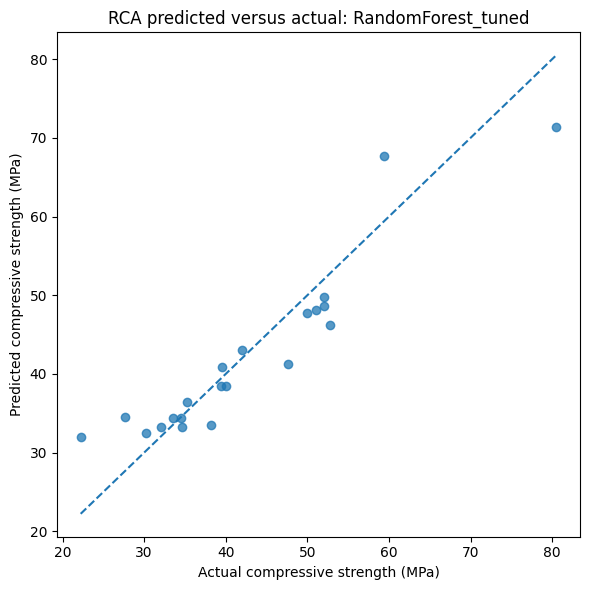

Saved: /content/figures/pred_vs_actual_RandomForest_tuned_rca.png


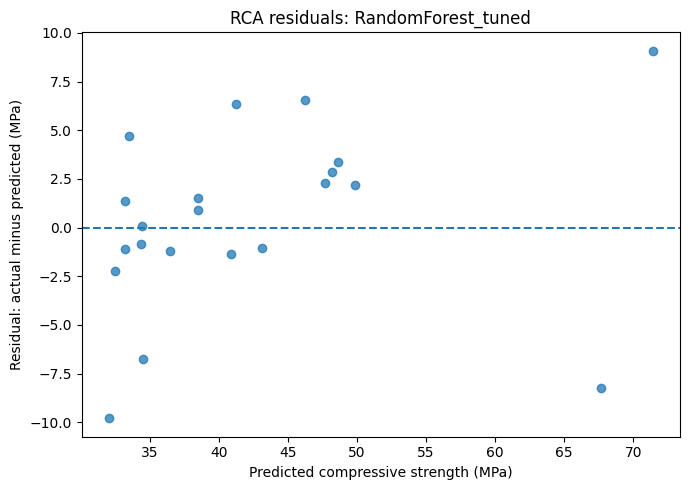

Saved: /content/figures/residual_plot_RandomForest_tuned_rca.png


In [14]:
# Defines the untuned version of the best performing model
# Used to determine if tuning was beneficial in improving model accuracy
untuned_same_family_name = (
    selected_name.replace(
        "_tuned",
        "",
    )
)

# Grabs the results of the untuned model
untuned_selected_row = (
    ablation_df[
        (
            ablation_df["feature_set"]
            == selected_feature_set_name
        )
        & (
            ablation_df["model"]
            == untuned_same_family_name
        )
    ]
)

if len(untuned_selected_row) == 1:
    untuned_family_cv_r2 = float(
        untuned_selected_row.iloc[0][
            "cv_r2_mean"
        ]
    )
else:
    untuned_family_cv_r2 = np.nan

# Compute the R^2 improvement from tuning the model
tuning_delta_cv_r2 = (
    candidate_cv_scores[
        selected_name
    ]
    - untuned_family_cv_r2
)

# Create a summary table of the results for viewing
# Acts as supporting evidence for how tuning affected model accuracy
tuning_effect_df = pd.DataFrame(
    [
        {
            "selected_model": selected_name,
            "untuned_family": (
                untuned_same_family_name
            ),
            "untuned_group_cv_r2": (
                untuned_family_cv_r2
            ),
            "tuned_group_cv_r2": (
                candidate_cv_scores[
                    selected_name
                ]
            ),
            "group_cv_r2_change": (
                tuning_delta_cv_r2
            ),
        }
    ]
)

tuning_effect_path = (
    OUT_DIR
    / "rca_tuning_effect_summary_rca.csv"
)

tuning_effect_df.to_csv(
    tuning_effect_path,
    index=False,
)

print("Saved:", tuning_effect_path)
display(tuning_effect_df)

# Creates a table comparing actual vs. predicted concrete compressive strength values
# Calculates residuals for concrete compressive strength
prediction_df = pd.DataFrame(
    {
        "source_row_number": (
            model_df[
                "source_row_number"
            ].iloc[test_idx].to_numpy()
        ),
        "actual_strength_mpa": (
            y_test.to_numpy()
        ),
        "predicted_strength_mpa": (
            selected_pred
        ),
    }
)

prediction_df["residual_mpa"] = (
    prediction_df[
        "actual_strength_mpa"
    ]
    - prediction_df[
        "predicted_strength_mpa"
    ]
)

prediction_df["absolute_error_mpa"] = (
    prediction_df[
        "residual_mpa"
    ].abs()
)

prediction_path = (
    OUT_DIR
    / (
        f"rca_test_predictions_"
        f"{selected_name}_rca.csv"
    )
)

prediction_df.to_csv(
    prediction_path,
    index=False,
)

print("Saved:", prediction_path)

# Predicted vs. Actual Strength Scatterplot
# Test how close the model comes to a 1:1 correlation to determine model accuracy
# Saved to figures for publication
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    prediction_df[
        "actual_strength_mpa"
    ],
    prediction_df[
        "predicted_strength_mpa"
    ],
    alpha=0.75,
)

# Places 45-degree line
# Provides a visual aid to determine model accuracy
limits = [
    min(
        prediction_df[
            "actual_strength_mpa"
        ].min(),
        prediction_df[
            "predicted_strength_mpa"
        ].min(),
    ),
    max(
        prediction_df[
            "actual_strength_mpa"
        ].max(),
        prediction_df[
            "predicted_strength_mpa"
        ].max(),
    ),
]

ax.plot(
    limits,
    limits,
    linestyle="--",
)

ax.set_xlabel(
    "Actual compressive strength (MPa)"
)
ax.set_ylabel(
    "Predicted compressive strength (MPa)"
)
ax.set_title(
    f"RCA predicted versus actual: {selected_name}"
)

fig.tight_layout()

fig_path = (
    FIG_DIR
    / (
        f"pred_vs_actual_"
        f"{selected_name}_rca.png"
    )
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

# Residuals graph (Negative = Overpredicted, Positive = Underpredicted)
# Provides another way to graph model accuracy
# Saved to figures for publication
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    prediction_df[
        "predicted_strength_mpa"
    ],
    prediction_df[
        "residual_mpa"
    ],
    alpha=0.75,
)

ax.axhline(
    0,
    linestyle="--",
)

ax.set_xlabel(
    "Predicted compressive strength (MPa)"
)
ax.set_ylabel(
    "Residual: actual minus predicted (MPa)"
)
ax.set_title(
    f"RCA residuals: {selected_name}"
)

fig.tight_layout()

fig_path = (
    FIG_DIR
    / (
        f"residual_plot_"
        f"{selected_name}_rca.png"
    )
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

**Predicted vs. Actual Scatterplot:** A test sample size of 21 mixtures was used with the tuned random forest model, with an R^2 value of 0.868, a MAE of 0.518, and a RMSE of 4.596. Most predictions follow the one-to-one line, but larger errors at lower and higher strength mixtures. This is consistent with the target and recycled aggregate distribution histograms, as less data exists at those ranges to train the models.

**Residuals Scatterplot:** The figure shows a large range for the residual values. Significant overpredictions and underpredictions exist at low and high predicted compressive strengths. More detailed conclusions cannot be reached due to the small test set.

Saved: /content/outputs/permutation_importance_RandomForest_tuned_rca.csv


,feature,importance_mean,importance_std
0,water_cement_ratio,1.145410,0.249060
1,water,0.219654,0.049177
2,cement,0.109296,0.029944
6,recycled_fine_aggregate,0.036405,0.012926
4,natural_coarse_aggregate,0.023020,0.023849
3,natural_fine_aggregate,0.018074,0.017747
5,recycled_coarse_aggregate,0.014151,0.008728


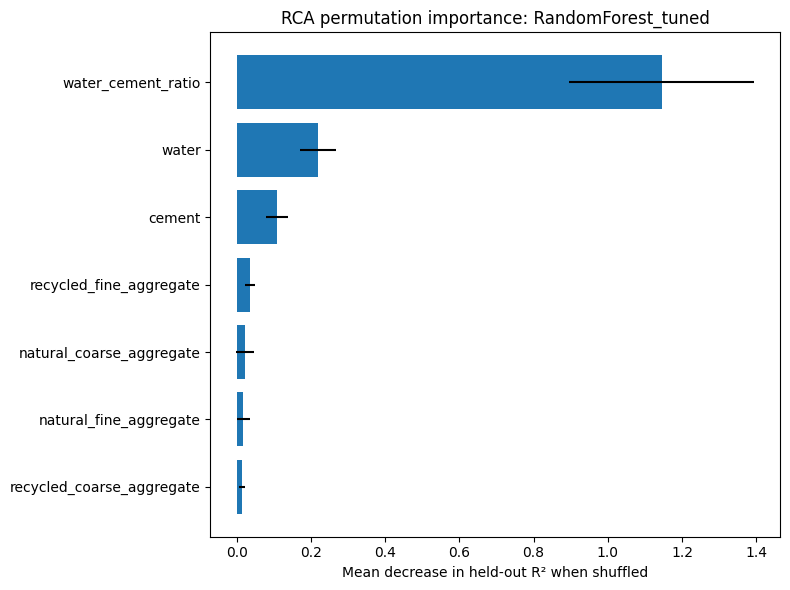

Saved: /content/figures/feature_importance_RandomForest_tuned_rca.png


In [15]:
# Measures importance of each variable using "r2" as a scoring metric
# Only refers to importance in predicting concrete compressive strength
# See more in graph explanations
permutation_result = permutation_importance(
    selected_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=RANDOM_STATE,
    scoring="r2",
)

# Sorts variables and provides mean + STD for each
importance_df = pd.DataFrame(
    {
        "feature": selected_features,
        "importance_mean": (
            permutation_result
            .importances_mean
        ),
        "importance_std": (
            permutation_result
            .importances_std
        ),
    }
).sort_values(
    "importance_mean",
    ascending=False,
)

# Saves table for publication
importance_path = (
    OUT_DIR
    / (
        f"permutation_importance_"
        f"{selected_name}_rca.csv"
    )
)

importance_df.to_csv(
    importance_path,
    index=False,
)

print("Saved:", importance_path)
display(importance_df)

# Permutation Importance Bar Graph plotting
fig, ax = plt.subplots(figsize=(8, 6))

top_importance = (
    importance_df
    .head(
        min(
            12,
            len(importance_df),
        )
    )
    .iloc[::-1]
)

ax.barh(
    top_importance["feature"],
    top_importance["importance_mean"],
    xerr=top_importance[
        "importance_std"
    ],
)

ax.set_xlabel(
    "Mean decrease in held-out R² when shuffled"
)
ax.set_title(
    f"RCA permutation importance: {selected_name}"
)

fig.tight_layout()

fig_path = (
    FIG_DIR
    / (
        f"feature_importance_"
        f"{selected_name}_rca.png"
    )
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

**Permutation Importance Bar Graph:** The water-cement ratio and water content of the mixtures are the strongest predictive variables within this fitted model. This also means that this importance is model-specific, and should not be considered direct physical or causal effects. Other features seem to be significantly less important in model predictions based on the permutation importance.

## 12. Repeated nested grouped model tuning using a preselected feature set

The primary hold-out result is only one split. This section repeats the full group-aware model-selection process across multiple outer grouped splits. Each outer split performs its own inner group-aware tuning before evaluating an untouched outer test subset.

These results provide a more realistic estimate of model-development variability than resampling one fixed set of predictions. However, due to the small number of mixtures, the grouped split only changes a small number of repeated mixtures. Exact-value grouped also does not necessarily prevent similar formulations or mixtures from appearing across different folds. Therefore, this is currently considered a limitation of the present study.

Saved: /content/outputs/rca_repeated_nested_group_validation_rca.csv
Saved: /content/outputs/rca_repeated_group_validation_summary_rca.csv


,split_number,selected_model,inner_group_cv_r2,outer_train_rows,outer_test_rows,r2,mae_mpa,rmse_mpa
0,1,RandomForest_tuned,0.726809,84,21,0.868093,3.521651,4.596152
1,2,GradientBoosting_tuned,0.762872,84,21,0.796189,4.161235,5.145543
2,3,RandomForest_tuned,0.796763,84,21,0.745016,4.677128,6.982757
3,4,RandomForest_tuned,0.757008,84,21,0.890753,3.133109,3.811540
4,5,GradientBoosting_tuned,0.791517,84,21,0.251412,4.276056,5.934920
5,6,RandomForest_tuned,0.656498,84,21,0.834989,4.103434,5.637034
6,7,GradientBoosting_tuned,0.759328,84,21,0.858974,3.216567,4.854444
7,8,RandomForest_tuned,0.794411,84,21,0.781503,4.123814,5.738279
8,9,GradientBoosting_tuned,0.837391,83,22,0.781121,4.312319,5.839575
9,10,GradientBoosting_tuned,0.673221,83,22,0.876660,3.857891,4.698516


,metric,median,iqr_25,iqr_75,range_2_5,range_97_5,minimum,maximum
0,r2,0.815589,0.781217,0.865813,0.362473,0.887582,0.251412,0.890753
1,mae_mpa,4.113624,3.605711,4.247351,3.151887,4.595046,3.133109,4.677128
2,rmse_mpa,5.391289,4.737498,5.814251,3.988078,6.746993,3.811540,6.982757


Model-selection counts:


,count
selected_model,
RandomForest_tuned,5
GradientBoosting_tuned,5


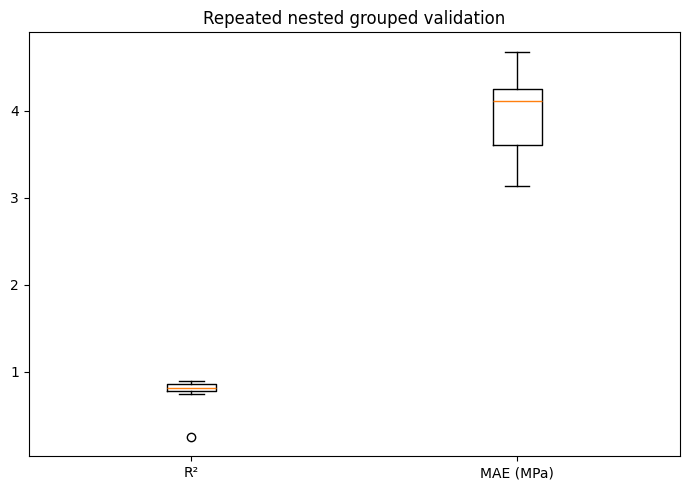

Saved: /content/figures/repeated_group_validation_rca.png


In [16]:
# Defines the input variables before setting up grouped splits
def tune_and_select_with_groups(
    X_outer_train,
    y_outer_train,
    groups_outer_train,
):
    # Sets a grouped 4-fold max cross-validation for tuning
    inner_cv = make_group_cv(
        groups_outer_train,
        maximum_splits=4,
    )

    # Runs random forest hyperparameter tuning and evaluated with grouped cross-valdiation
    rf_inner = GridSearchCV(
        RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        RF_GRID,
        cv=inner_cv,
        scoring="r2",
        n_jobs=-1,
    )

    # Runs gradient boosting hyperparameter tuning and evaluated with grouped cross-valdiation
    gb_inner = GridSearchCV(
        GradientBoostingRegressor(
            random_state=RANDOM_STATE,
        ),
        GBR_GRID,
        cv=inner_cv,
        scoring="r2",
        n_jobs=-1,
    )

    # Runs a grid search to train both the random forest and gradient boosting models
    # Uses the training set data and hyperparameter tuning for optimal configurations
    rf_inner.fit(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
    )

    gb_inner.fit(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
    )

    # Evaluates the linear regression model
    linear_inner = cross_validate(
        clone(linear_estimator),
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
        cv=inner_cv,
        scoring="r2",
        n_jobs=1,
    )

    # Scores each model using R^2 values
    # Used later for determining the best model
    scores = {
        "LinearRegression": (
            linear_inner[
                "test_score"
            ].mean()
        ),
        "RandomForest_tuned": (
            rf_inner.best_score_
        ),
        "GradientBoosting_tuned": (
            gb_inner.best_score_
        ),
    }

    # Displays the optimal hyperparameters for each model
    # Helps with reproducibility alongside randomstate variable
    estimators = {
        "LinearRegression": (
            clone(linear_estimator)
        ),
        "RandomForest_tuned": (
            clone(
                rf_inner.best_estimator_
            )
        ),
        "GradientBoosting_tuned": (
            clone(
                gb_inner.best_estimator_
            )
        ),
    }

    # Defines the best model off of the ranked R^2 scores
    best_name = max(
        scores,
        key=scores.get,
    )

    return (
        best_name,
        estimators[best_name],
        scores[best_name],
    )

# Repeated validation part of the code
# Creates multiple train/test splits for model evaluation
outer_splitter = GroupShuffleSplit(
    n_splits=N_REPEATED_GROUP_SPLITS,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

# Initialize an empty list
repeated_rows = []

# Reruns a similar evaluation as the previous code for each model multiple times
    # Starts with hyperparameter tuning and selecting the best model
    # The model is trained on one set of data and tested on another
    # The model performance is then saved and the process repeats
for split_number, (
    outer_train_idx,
    outer_test_idx,
) in enumerate(
    outer_splitter.split(
        X_selected,
        model_df[TARGET_COL],
        groups=mix_groups,
    ),
    start=1,
):
    X_outer_train = (
        X_selected
        .iloc[outer_train_idx]
        .copy()
    )

    X_outer_test = (
        X_selected
        .iloc[outer_test_idx]
        .copy()
    )

    y_outer_train = (
        model_df[TARGET_COL]
        .iloc[outer_train_idx]
        .copy()
    )

    y_outer_test = (
        model_df[TARGET_COL]
        .iloc[outer_test_idx]
        .copy()
    )

    groups_outer_train = (
        mix_groups.iloc[
            outer_train_idx
        ]
    )

    groups_outer_test = (
        mix_groups.iloc[
            outer_test_idx
        ]
    )

    # Checks for train/test split leakage
    if set(
        groups_outer_train
    ).intersection(
        set(groups_outer_test)
    ):
        raise RuntimeError(
            "Group leakage detected in repeated validation."
        )

    (
        split_model_name,
        split_model,
        inner_cv_r2,
    ) = tune_and_select_with_groups(
        X_outer_train,
        y_outer_train,
        groups_outer_train,
    )

    split_model.fit(
        X_outer_train,
        y_outer_train,
    )

    split_prediction = split_model.predict(
        X_outer_test
    )

    split_metrics = evaluate_predictions(
        y_outer_test,
        split_prediction,
    )

    repeated_rows.append(
        {
            "split_number": split_number,
            "selected_model": (
                split_model_name
            ),
            "inner_group_cv_r2": (
                inner_cv_r2
            ),
            "outer_train_rows": (
                len(outer_train_idx)
            ),
            "outer_test_rows": (
                len(outer_test_idx)
            ),
            **split_metrics,
        }
    )

# Saves the results of all the repeated splits
repeated_validation_df = pd.DataFrame(
    repeated_rows
)

# Saves nested group validation results to an output for publication
repeated_path = (
    OUT_DIR
    / "rca_repeated_nested_group_validation_rca.csv"
)

repeated_validation_df.to_csv(
    repeated_path,
    index=False,
)

# Initialize an empty list
metric_summary_rows = []

# Creates and calculates a summary of the models distribution of performance
# Asks how the model predictive accuracy differs across different percentiles
for metric in [
    "r2",
    "mae_mpa",
    "rmse_mpa",
]:
    metric_summary_rows.append(
        {
            "metric": metric,
            "median": (
                repeated_validation_df[
                    metric
                ].median()
            ),
            "iqr_25": (
                repeated_validation_df[
                    metric
                ].quantile(0.25)
            ),
            "iqr_75": (
                repeated_validation_df[
                    metric
                ].quantile(0.75)
            ),
            "range_2_5": (
                repeated_validation_df[
                    metric
                ].quantile(0.025)
            ),
            "range_97_5": (
                repeated_validation_df[
                    metric
                ].quantile(0.975)
            ),
            "minimum": (
                repeated_validation_df[
                    metric
                ].min()
            ),
            "maximum": (
                repeated_validation_df[
                    metric
                ].max()
            ),
        }
    )

repeated_summary_df = pd.DataFrame(
    metric_summary_rows
)

# Saves results to outputs for model analysis
repeated_summary_path = (
    OUT_DIR
    / "rca_repeated_group_validation_summary_rca.csv"
)

repeated_summary_df.to_csv(
    repeated_summary_path,
    index=False,
)

# Displays all the results for user confirmation
print("Saved:", repeated_path)
print("Saved:", repeated_summary_path)

display(repeated_validation_df)
display(repeated_summary_df)

print("Model-selection counts:")
display(
    repeated_validation_df[
        "selected_model"
    ].value_counts()
)

# Regression Evaluation Metrics Boxplot
# Shows the distributions of R^2 and MAE
fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot(
    [
        repeated_validation_df["r2"],
        repeated_validation_df["mae_mpa"],
    ],
    tick_labels=[
        "R²",
        "MAE (MPa)",
    ],
)

ax.set_title(
    "Repeated nested grouped validation"
)

fig.tight_layout()

fig_path = (
    FIG_DIR
    / "repeated_group_validation_rca.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_path)

**Result Interpretation:** Since both the random forest and gradient boosting are selected an equal amount of times, it's likely that the amount of data is insufficient to determine the better model. Therefore, neither model family should be considered dominant over the other in the context of this notebook.

## 13. Error analysis by recycled fraction and strength range

Subgroup results are reported with their sample counts. Small subgroups are interpreted cautiously.

In [34]:
# Creates a separate DataFrame of the held-out test set
heldout_df = (
    model_df.iloc[test_idx]
    .copy()
    .reset_index(drop=True)
)

# Adds model predictions to the DataFrame
# Used to check if the model performs better/worse for different values later in the code
heldout_df[
    "predicted_strength_mpa"
] = selected_pred

# Uses absolute error prediction
heldout_df["absolute_error_mpa"] = (
    heldout_df[TARGET_COL]
    - heldout_df[
        "predicted_strength_mpa"
    ]
).abs()

# Splits RA fraction into 4 groups and drops duplicates
# q=4 represents 4 quartiles
heldout_df[
    "recycled_fraction_group"
] = pd.qcut(
    heldout_df[
        "recycled_aggregate_fraction"
    ],
    q=4,
    duplicates="drop",
)

# Splits concrete compressive strength into quartiles
heldout_df[
    "strength_band_mpa"
] = pd.qcut(
    heldout_df[TARGET_COL],
    q=4,
    labels=[
        "Q1 (lowest strength)",
        "Q2",
        "Q3",
        "Q4 (highest strength)",
    ],
    duplicates="drop"
)

# Analyzes the prediction errors of each quartile/range
# Tests if the model predicts certain mixtures more accurately
error_by_recycled_fraction = (
    heldout_df
    .groupby(
        "recycled_fraction_group",
        observed=True,
    )["absolute_error_mpa"]
    .agg(
        [
            "count",
            "mean",
            "median",
            "max",
        ]
    )
    .reset_index()
)

error_by_strength_band = (
    heldout_df
    .groupby(
        "strength_band_mpa",
        observed=True,
    )["absolute_error_mpa"]
    .agg(
        [
            "count",
            "mean",
            "median",
            "max",
        ]
    )
    .reset_index()
)

# Saves the results to outputs for publication
# Results suggest what ranges the model performs best in
fraction_error_path = (
    OUT_DIR
    / "error_by_recycled_fraction_rca.csv"
)

strength_error_path = (
    OUT_DIR
    / "error_by_strength_band_rca.csv"
)

error_by_recycled_fraction.to_csv(
    fraction_error_path,
    index=False,
)

error_by_strength_band.to_csv(
    strength_error_path,
    index=False,
)

# Displays results for user manual review
print("Saved:", fraction_error_path)
print("Saved:", strength_error_path)

display(error_by_recycled_fraction)
display(error_by_strength_band)

Saved: /content/outputs/error_by_recycled_fraction_rca.csv
Saved: /content/outputs/error_by_strength_band_rca.csv


,recycled_fraction_group,count,mean,median,max
0,"(0.221, 0.283]",6,2.264367,1.427572,6.569015
1,"(0.283, 0.401]",5,1.624208,1.100175,4.716076
2,"(0.401, 0.456]",5,4.531061,3.361501,9.087039
3,"(0.456, 0.647]",5,5.904493,6.344772,9.802685


,strength_band_mpa,count,mean,median,max
0,Q1 (lowest strength),6,3.474991,1.673425,9.802685
1,Q2,5,1.909206,1.340488,4.716076
2,Q3,5,2.813483,2.302993,6.344772
3,Q4 (highest strength),5,5.884326,6.569015,9.087039


## 14. Out-of-fold predictions for candidate analysis

After final evaluation, the selected model configuration is used to generate group-aware out-of-fold predictions for every cleaned observation. These predictions are used for the Pareto analysis so that each row is predicted by a model that was not trained on that row's mixture group.

In [18]:
# Creates a 5-fold grouped cross-validation
# This does not contain train/test split and the entire dataset is used
all_group_cv = make_group_cv(
    mix_groups,
    maximum_splits=5,
)

# Runs out-of-fold (oof) predictions
# Predicts 1 fold while training the model on the remaining 4 folds
# This is done for each fold until they have all been predicted
oof_prediction = cross_val_predict(
    clone(selected_model),
    X_selected,
    model_df[TARGET_COL],
    groups=mix_groups,
    cv=all_group_cv,
    n_jobs=1,
)

# Creates a copy of the original data
# Adds oof predictions and absolute error
candidate_df = model_df.copy()

candidate_df[
    "oof_predicted_strength_mpa"
] = oof_prediction

candidate_df[
    "oof_absolute_error_mpa"
] = (
    candidate_df[TARGET_COL]
    - candidate_df[
        "oof_predicted_strength_mpa"
    ]
).abs()

# Computes relevant metrics (R^2, MAE, RMSE)
# Effectively the same as models trained on a train/test split due to oof prediction
oof_metrics = evaluate_predictions(
    candidate_df[TARGET_COL],
    candidate_df[
        "oof_predicted_strength_mpa"
    ],
)

# Creates a table of all relevant information, then saves to outputs for publication
oof_summary_df = pd.DataFrame(
    [
        {
            "prediction_type": (
                "grouped out-of-fold"
            ),
            **oof_metrics,
        }
    ]
)

oof_path = (
    OUT_DIR
    / "rca_grouped_oof_predictions_rca.csv"
)

candidate_df.to_csv(
    oof_path,
    index=False,
)

# Prints for user confirmation
print("Saved:", oof_path)
display(oof_summary_df)

Saved: /content/outputs/rca_grouped_oof_predictions_rca.csv


,prediction_type,r2,mae_mpa,rmse_mpa
0,grouped out-of-fold,0.813885,3.876144,5.350369


## 15. Sustainability-factor scenarios

The proxy uses three literature-informed scenarios because published factors vary by geography, production process, transport, and system boundary.

The scenarios are not statistical confidence intervals:

- **Low-impact factor case:** lower-impact production assumptions.
- **Central factor case:** representative working values.
- **High-impact factor case:** higher-impact production assumptions.

All values are in `kg CO₂e/kg material`. Multiplication by mixture quantities in `kg/m³` produces `kg CO₂e/m³`.

This remains a simplified cradle-to-gate-style proxy and must not be described as a full LCA, but rather an emissions proxy. Additionally, until the reported aggregate-cement ratio agrees with the calculated ratio from Section 5, this should be considered a preliminary sensitivity analysis rather than final sustainability findings.

In [19]:
# Assigns CO2 values to each variable and notes the source of those values
# Used as an alternative if a CSV isn't uploaded to the notebook
DEFAULT_FACTOR_SCENARIOS = pd.DataFrame(
    [
        # Cement
        {
            "scenario": "low",
            "material": "cement",
            "co2_kg_per_kg": 0.8726,
            "source": (
                "Environmental Performance of "
                "Deconstructable Concrete Beams"
            ),
            "doi": "10.3390/su141811457",
            "original_value": "0.8726",
            "original_unit": "kg CO2e/kg",
            "conversion": "none",
            "geography_or_context": (
                "source-specific concrete LCA"
            ),
        },
        {
            "scenario": "central",
            "material": "cement",
            "co2_kg_per_kg": 0.9120,
            "source": "ICE Database value reported in concrete LCA literature",
            "doi": "",
            "original_value": "0.9120",
            "original_unit": "kg CO2e/kg",
            "conversion": "none",
            "geography_or_context": "database-derived working value",
        },
        {
            "scenario": "high",
            "material": "cement",
            "co2_kg_per_kg": 1.0020,
            "source": "Carbon Emission Evaluation of CO2 Curing in Recycled-Aggregate Concrete",
            "doi": "10.3390/ma16062436",
            "original_value": "1.002",
            "original_unit": "kg CO2e/kg",
            "conversion": "none",
            "geography_or_context": "source-specific concrete LCA",
        },

        # Water
        {
            "scenario": "low",
            "material": "water",
            "co2_kg_per_kg": 0.000196,
            "source": "Project baseline proxy documentation",
            "doi": "",
            "original_value": "0.196",
            "original_unit": "kg CO2e/m3 water",
            "conversion": "divide by 1000 kg water per m3",
            "geography_or_context": "working value",
        },
        {
            "scenario": "central",
            "material": "water",
            "co2_kg_per_kg": 0.000300,
            "source": "ICE Database value reported in concrete LCA literature",
            "doi": "",
            "original_value": "0.0003",
            "original_unit": "kg CO2e/kg",
            "conversion": "none",
            "geography_or_context": "database-derived working value",
        },
        {
            "scenario": "high",
            "material": "water",
            "co2_kg_per_kg": 0.000410,
            "source": "Review of Waste Materials in Rigid Airport Pavements",
            "doi": "10.3390/su17156959",
            "original_value": "0.00041",
            "original_unit": "kg CO2e/kg",
            "conversion": "none",
            "geography_or_context": "source-specific concrete inventory",
        },

        # Natural fine aggregate
        {
            "scenario": "low",
            "material": "natural_fine_aggregate",
            "co2_kg_per_kg": 0.00221,
            "source": "Environmental Evaluation of Concrete Containing Recycled and By-Product Aggregates",
            "doi": "10.3390/app10217503",
            "original_value": "0.00221",
            "original_unit": "kg CO2e/kg sand",
            "conversion": "none",
            "geography_or_context": "Korean LCI database",
        },
        {
            "scenario": "central",
            "material": "natural_fine_aggregate",
            "co2_kg_per_kg": 0.00550,
            "source": "Review of Waste Materials in Rigid Airport Pavements",
            "doi": "10.3390/su17156959",
            "original_value": "0.0055",
            "original_unit": "kg CO2e/kg natural aggregate",
            "conversion": "none",
            "geography_or_context": "reviewed inventory value",
        },
        {
            "scenario": "high",
            "material": "natural_fine_aggregate",
            "co2_kg_per_kg": 0.03140,
            "source": "Shear Response of Recycled Aggregates Concrete Deep Beams",
            "doi": "10.3390/su14020945",
            "original_value": "0.0052 to 0.0314",
            "original_unit": "kg CO2e/kg natural aggregate",
            "conversion": "upper end of reported range",
            "geography_or_context": "compiled source range",
        },

        # Natural coarse aggregate
        {
            "scenario": "low",
            "material": "natural_coarse_aggregate",
            "co2_kg_per_kg": 0.00410,
            "source": "Carbon Emission Evaluation of CO2 Curing in Recycled-Aggregate Concrete",
            "doi": "10.3390/ma16062436",
            "original_value": "0.00410",
            "original_unit": "kg CO2e/kg coarse gravel",
            "conversion": "none",
            "geography_or_context": "source-specific concrete inventory",
        },
        {
            "scenario": "central",
            "material": "natural_coarse_aggregate",
            "co2_kg_per_kg": 0.01430,
            "source": "Analysis of Life Cycle Environmental Impact of Recycled Aggregate",
            "doi": "10.3390/app9051021",
            "original_value": "0.0143",
            "original_unit": "kg CO2e/kg natural gravel",
            "conversion": "none",
            "geography_or_context": "Korean cradle-to-gate aggregate production",
        },
        {
            "scenario": "high",
            "material": "natural_coarse_aggregate",
            "co2_kg_per_kg": 0.03140,
            "source": "Shear Response of Recycled Aggregates Concrete Deep Beams",
            "doi": "10.3390/su14020945",
            "original_value": "0.0052 to 0.0314",
            "original_unit": "kg CO2e/kg natural aggregate",
            "conversion": "upper end of reported range",
            "geography_or_context": "compiled source range",
        },

        # Recycled fine aggregate
        {
            "scenario": "low",
            "material": "recycled_fine_aggregate",
            "co2_kg_per_kg": 0.00140,
            "source": "Environmental Performance of Deconstructable Concrete Beams",
            "doi": "10.3390/su141811457",
            "original_value": "0.0014",
            "original_unit": "kg CO2e/kg recycled aggregate",
            "conversion": "none",
            "geography_or_context": "electricity-based processing scenario",
        },
        {
            "scenario": "central",
            "material": "recycled_fine_aggregate",
            "co2_kg_per_kg": 0.01490,
            "source": "Environmental Evaluation of Concrete Containing Recycled and By-Product Aggregates",
            "doi": "10.3390/app10217503",
            "original_value": "0.0149",
            "original_unit": "kg CO2e/kg recycled aggregate",
            "conversion": "none",
            "geography_or_context": "Korean LCI database",
        },
        {
            "scenario": "high",
            "material": "recycled_fine_aggregate",
            "co2_kg_per_kg": 0.03810,
            "source": "Analysis of Life Cycle Environmental Impact of Recycled Aggregate",
            "doi": "10.3390/app9051021",
            "original_value": "0.0381",
            "original_unit": "kg CO2e/kg wet recycled aggregate",
            "conversion": "none",
            "geography_or_context": "wet-processing cradle-to-gate scenario",
        },

        # Recycled coarse aggregate
        {
            "scenario": "low",
            "material": "recycled_coarse_aggregate",
            "co2_kg_per_kg": 0.00140,
            "source": "Environmental Performance of Deconstructable Concrete Beams",
            "doi": "10.3390/su141811457",
            "original_value": "0.0014",
            "original_unit": "kg CO2e/kg recycled aggregate",
            "conversion": "none",
            "geography_or_context": "electricity-based processing scenario",
        },
        {
            "scenario": "central",
            "material": "recycled_coarse_aggregate",
            "co2_kg_per_kg": 0.01490,
            "source": "Environmental Evaluation of Concrete Containing Recycled and By-Product Aggregates",
            "doi": "10.3390/app10217503",
            "original_value": "0.0149",
            "original_unit": "kg CO2e/kg recycled aggregate",
            "conversion": "none",
            "geography_or_context": "Korean LCI database",
        },
        {
            "scenario": "high",
            "material": "recycled_coarse_aggregate",
            "co2_kg_per_kg": 0.03810,
            "source": "Analysis of Life Cycle Environmental Impact of Recycled Aggregate",
            "doi": "10.3390/app9051021",
            "original_value": "0.0381",
            "original_unit": "kg CO2e/kg wet recycled aggregate",
            "conversion": "none",
            "geography_or_context": "wet-processing cradle-to-gate scenario",
        },
    ]
)

# Searches for a CSV to record numeric values and citations
factor_path = (
    DATA_DIR
    / "rca_sustainability_factor_scenarios.csv"
)

if factor_path.exists():
    factor_scenarios = pd.read_csv(
        factor_path
    )
    print(
        "Using repository factor scenarios:",
        factor_path,
    )

# If not, use the recorded values in the notebook code
else:
    factor_scenarios = (
        DEFAULT_FACTOR_SCENARIOS.copy()
    )
    print(
        "Using embedded factor scenarios. "
        "Commit the companion CSV to data/ "
        "for the final repository."
    )

# Checks for missing required columns before continuing to calculations
required_factor_columns = {
    "scenario",
    "material",
    "co2_kg_per_kg",
    "source",
    "doi",
    "original_value",
    "original_unit",
    "conversion",
    "geography_or_context",
}

missing_factor_columns = (
    required_factor_columns
    - set(factor_scenarios.columns)
)

if missing_factor_columns:
    raise ValueError(
        "Sustainability factor table is missing columns: "
        f"{sorted(missing_factor_columns)}"
    )

# Makes sure that CO2 values are reasonable or if any input errors were made
# Attempts to coerce errrors before returning an error message, if possible
factor_scenarios[
    "co2_kg_per_kg"
] = pd.to_numeric(
    factor_scenarios[
        "co2_kg_per_kg"
    ],
    errors="coerce",
)

if (
    factor_scenarios[
        "co2_kg_per_kg"
    ].isna().any()
    or (
        factor_scenarios[
            "co2_kg_per_kg"
        ] < 0
    ).any()
):
    raise ValueError(
        "All emissions factors must be numeric and nonnegative."
    )

# Checks if all the required materials are present in the CSV defined by the previous code
required_materials = [
    "cement",
    "water",
    "natural_fine_aggregate",
    "natural_coarse_aggregate",
    "recycled_fine_aggregate",
    "recycled_coarse_aggregate",
]

for scenario_name in [
    "low",
    "central",
    "high",
]:
    scenario_materials = set(
        factor_scenarios.loc[
            factor_scenarios[
                "scenario"
            ]
            == scenario_name,
            "material",
        ]
    )

    missing_materials = (
        set(required_materials)
        - scenario_materials
    )

    if missing_materials:
        raise ValueError(
            f"Scenario '{scenario_name}' is missing materials: "
            f"{sorted(missing_materials)}"
        )

# Saves sustainability CSV to outputs for publication and prints for manual review
factor_used_path = (
    OUT_DIR
    / "rca_sustainability_factor_scenarios_used_rca.csv"
)

factor_scenarios.to_csv(
    factor_used_path,
    index=False,
)

print("Saved:", factor_used_path)
display(factor_scenarios)

Using repository factor scenarios: /content/data/rca_sustainability_factor_scenarios.csv
Saved: /content/outputs/rca_sustainability_factor_scenarios_used_rca.csv


,scenario,material,co2_kg_per_kg,source,doi,original_value,original_unit,conversion,geography_or_context
0,low,cement,0.872600,Environmental Performance of Deconstructable C...,10.3390/su141811457,0.8726,kg CO2e/kg,none,source-specific concrete LCA
1,central,cement,0.912000,ICE Database value reported in concrete LCA li...,NaN,0.912,kg CO2e/kg,none,database-derived working value
2,high,cement,1.002000,Carbon Emission Evaluation of CO2 Curing in Re...,10.3390/ma16062436,1.002,kg CO2e/kg,none,source-specific concrete LCA
3,low,water,0.000196,Project baseline proxy documentation,NaN,0.196,kg CO2e/m3 water,divide by 1000 kg water per m3,working value
4,central,water,0.000300,ICE Database value reported in concrete LCA li...,NaN,0.0003,kg CO2e/kg,none,database-derived working value
5,high,water,0.000410,Review of Waste Materials in Rigid Airport Pav...,10.3390/su17156959,0.00041,kg CO2e/kg,none,source-specific concrete inventory
6,low,natural_fine_aggregate,0.002210,Environmental Evaluation of Concrete Containin...,10.3390/app10217503,0.00221,kg CO2e/kg sand,none,Korean LCI database
7,central,natural_fine_aggregate,0.005500,Review of Waste Materials in Rigid Airport Pav...,10.3390/su17156959,0.0055,kg CO2e/kg natural aggregate,none,reviewed inventory value
8,high,natural_fine_aggregate,0.031400,Shear Response of Recycled Aggregates Concrete...,10.3390/su14020945,0.0052 to 0.0314,kg CO2e/kg natural aggregate,upper end of reported range,compiled source range
9,low,natural_coarse_aggregate,0.004100,Carbon Emission Evaluation of CO2 Curing in Re...,10.3390/ma16062436,0.0041,kg CO2e/kg coarse gravel,none,source-specific concrete inventory


**Result Interpretation:** Since the values are pulled from multiple sources across features, with different system boundaries, locations, and studies, the following Pareto analysis should be considered an emissions proxy, not a complete  LCA. Unlike the previous notebooks, cost analysis is not included in the present notebook.

## 16. Scenario-based emissions proxy and Pareto stability

The frontier uses grouped out-of-fold predicted strength for every cleaned mixture. A candidate is considered stable when it remains nondominated under all three emissions-factor scenarios.

Saved: /content/outputs/rca_sustainability_and_pareto_sensitivity_rca.csv
Saved: /content/outputs/predicted_stable_pareto_candidates_rca.csv
Saved: /content/outputs/measured_stable_pareto_candidates_rca.csv
Saved: /content/outputs/pareto_scenario_summary_rca.csv


,scenario,predicted_pareto_candidate_count,measured_pareto_candidate_count,total_mixtures
0,low,19,17,105
1,central,17,19,105
2,high,15,18,105


Predicted stable Pareto candidates: 13
Measured stable Pareto candidates: 10


,source_row_number,cement,water,natural_fine_aggregate,natural_coarse_aggregate,recycled_fine_aggregate,recycled_coarse_aggregate,recycled_aggregate_fraction,compressive_strength_mpa,oof_predicted_strength_mpa,strength_prediction_difference_mpa,absolute_prediction_error_mpa,co2_proxy_low_kg_per_m3,co2_proxy_central_kg_per_m3,co2_proxy_high_kg_per_m3
26,28,300.0,150.0,734.0,657.000000,202.450000,550.000000,0.351046,33.1,34.592235,-1.492235,1.492235,267.178670,298.288605,373.007245
24,26,300.0,150.0,734.0,1314.000000,214.333333,343.333333,0.214021,35.8,35.050920,0.749080,0.749080,269.599673,304.781433,386.215800
6,8,350.0,140.0,728.0,652.000000,162.371026,550.000000,0.340461,37.1,36.967664,0.132336,0.132336,310.716839,343.183928,421.230736
52,54,350.0,180.0,706.0,647.000000,198.403333,1089.000000,0.487578,47.6,38.594855,9.005145,9.005145,311.460605,351.571410,442.308067
63,65,350.0,180.0,675.0,949.000000,198.403333,1089.000000,0.442193,49.2,41.149911,8.050089,8.050089,312.630295,355.719510,450.817467
66,68,425.0,185.0,618.0,823.333333,199.646667,982.000000,0.450498,57.3,45.541693,11.758307,11.758307,377.287012,420.434702,516.204455
56,58,425.0,185.0,696.0,962.333333,199.646667,1028.000000,0.425383,60.0,56.150985,3.849015,3.849015,378.093692,423.536802,524.770855
69,71,440.0,155.0,666.0,670.000000,198.403333,1077.000000,0.488398,69.8,65.566236,4.233764,4.233764,389.978805,433.574010,531.486817
61,63,485.0,165.0,685.0,910.000000,199.646667,979.000000,0.424945,71.2,69.623670,1.576330,1.576330,430.138295,476.711835,581.027088
59,61,485.0,165.0,685.0,1089.000000,214.333333,1031.666667,0.412583,80.5,71.173528,9.326472,9.326472,430.966490,480.275100,589.213850


,source_row_number,cement,water,natural_fine_aggregate,natural_coarse_aggregate,recycled_fine_aggregate,recycled_coarse_aggregate,recycled_aggregate_fraction,compressive_strength_mpa,oof_predicted_strength_mpa,strength_prediction_difference_mpa,absolute_prediction_error_mpa,co2_proxy_low_kg_per_m3,co2_proxy_central_kg_per_m3,co2_proxy_high_kg_per_m3
26,28,300.0,150.00,734.00,657.000000,202.450000,550.000000,0.351046,33.1,34.592235,-1.492235,1.492235,267.178670,298.288605,373.007245
1,3,300.0,120.00,763.00,1025.000000,549.403333,290.000000,0.319480,33.2,36.466477,-3.266477,3.266477,268.867415,304.997110,388.773667
30,32,350.0,175.00,694.00,621.000000,202.450000,520.000000,0.354585,35.8,37.145767,-1.345767,1.345767,310.535570,342.714305,419.588095
17,19,350.0,157.50,711.00,955.000000,206.790000,270.000000,0.222509,38.9,38.765422,0.134578,0.134578,311.595186,343.918421,421.242674
64,66,350.0,180.00,654.00,823.333333,198.403333,1041.000000,0.456210,43.6,42.959356,0.640644,0.640644,312.001451,353.091776,444.383334
84,86,400.0,212.27,634.49,558.370000,341.370000,273.530000,0.340145,49.0,49.542369,-0.542369,0.542369,353.634005,385.500077,461.770525
74,76,400.0,197.37,1008.85,568.960000,344.910000,278.730000,0.283286,52.0,50.649670,1.350330,1.350330,354.514075,387.836250,474.184840
56,58,425.0,185.00,696.00,962.333333,199.646667,1028.000000,0.425383,60.0,56.150985,3.849015,3.849015,378.093692,423.536802,524.770855
68,70,440.0,155.00,666.00,670.000000,198.403333,1070.000000,0.487023,59.4,67.930731,-8.530731,8.530731,389.969005,433.469710,531.220117
70,72,440.0,155.00,666.00,670.000000,198.403333,1083.000000,0.489570,67.8,67.996690,-0.196690,0.196690,389.987205,433.663410,531.715417


Measured-strength stable Pareto candidates
OOF-predicted-strength stable Pareto candidates
Saved: /content/figures/measured_vs_predicted_stable_pareto_frontiers_rca.png


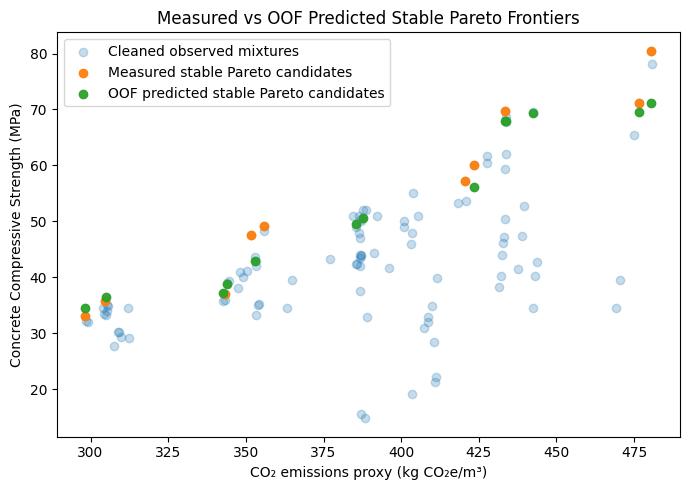

In [21]:
# Calculates the emissions proxy in Numpy
# Returns results to pandas Series; results ready to be saved
def calculate_emissions_proxy(
    frame,
    scenario_factors,
):
    factor_series = (
        scenario_factors
        .set_index("material")[
            "co2_kg_per_kg"
        ]
    )

    total = np.zeros(
        len(frame),
        dtype=float,
    )

    for material in required_materials:
        total += (
            frame[material]
            .to_numpy(dtype=float)
            * float(
                factor_series.loc[
                    material
                ]
            )
        )

    return pd.Series(
        total,
        index=frame.index,
    )

# Used to minimize emissions while maximizing strength
# Removes dominated mixes (non-Pareto optimal)
def nondominated_emissions_strength(
    emissions,
    strengths,
):
    keep = np.ones(
        len(strengths),
        dtype=bool,
    )

    for index in range(len(strengths)):
        dominates_index = (
            (emissions <= emissions[index])
            & (strengths >= strengths[index])
            & (
                (emissions < emissions[index])
                | (
                    strengths
                    > strengths[index]
                )
            )
        )

        if dominates_index.any():
            keep[index] = False

    return keep

# Initialize an empty list
scenario_results = []

# Searches for emission scenarios before grouping them
for scenario_name in [
    "low",
    "central",
    "high",
]:
    # Selects a single emission scenario and only selects factors based on that value
    # Done to check if Pareto-optimal mixtures hold up across all 3 scenarios
    scenario_factors = factor_scenarios[
        factor_scenarios[
            "scenario"
        ]
        == scenario_name
    ]

    # Defines a variable before computing CO2 emissions
    emissions_column = (
        f"co2_proxy_{scenario_name}_"
        "kg_per_m3"
    )

    # Adds estimated emissions for each mixture to the DataFrame
    # Labeled differently based on the emission scenario
    candidate_df[
        emissions_column
    ] = calculate_emissions_proxy(
        candidate_df,
        scenario_factors,
    )

    # Identifies the Pareto-optimal mixtures in the DataFrame
    # Checks for lower emissions and higher predicted strength

    # Pareto frontier using OOF predicted strength
    candidate_df[
        f"is_pareto_predicted_{scenario_name}"
        ] = (
        nondominated_emissions_strength(
            candidate_df[
                emissions_column
            ].to_numpy(),
            candidate_df[
                "oof_predicted_strength_mpa"
            ].to_numpy(),
        )
    )

    # Pareto frontier using measured strength
    candidate_df[
        f"is_pareto_measured_{scenario_name}"
        ] = (
        nondominated_emissions_strength(
            candidate_df[
                emissions_column
            ].to_numpy(),
            candidate_df[
                TARGET_COL
            ].to_numpy(),
        )
    )



    # Stores the Pareto candidates for future outputs
    scenario_results.append(
        {
            "scenario": scenario_name,
            "predicted_pareto_candidate_count": int(
                candidate_df[
                    f"is_pareto_predicted_{scenario_name}"
                ].sum()
            ),
            "measured_pareto_candidate_count": int(
                candidate_df[
                    f"is_pareto_measured_{scenario_name}"
                ].sum()
            ),
            "total_mixtures": len(candidate_df),
        }
    )

# Checks if the mixture stays Pareto-optimal across all 3 scenarios
# Assigns a numeric value from 1-3 based on how many scenarios the mixture was non-dominated

# Counts how many scenarios each mixture is Pareto-optimal for predicted strength
candidate_df[
    "predicted_pareto_selection_count"
] = (
    candidate_df[
        [
            "is_pareto_predicted_low",
            "is_pareto_predicted_central",
            "is_pareto_predicted_high",
        ]
    ]
    .sum(axis=1)
)

# Counts how many scenarios each mixture is Pareto-optimal for measured strength
candidate_df[
    "measured_pareto_selection_count"
] = (
    candidate_df[
        [
            "is_pareto_measured_low",
            "is_pareto_measured_central",
            "is_pareto_measured_high",
        ]
    ]
    .sum(axis=1)
)

# Determines if a non-dominated mixture is "stable"
# Uses different pareto_selection_count variables as the main way of determining this information
# Extracts Pareto-optimal mixtures before ranking them
predicted_stable_pareto_candidates = (
    candidate_df[
        candidate_df[
            "predicted_pareto_selection_count"
        ] == 3
    ]
    .sort_values(
        [
            "co2_proxy_central_kg_per_m3",
            "oof_predicted_strength_mpa",
        ],
        ascending=[
            True,
            False,
        ],
    )
)


measured_stable_pareto_candidates = (
    candidate_df[
        candidate_df[
            "measured_pareto_selection_count"
        ] == 3
    ]
    .sort_values(
        [
            "co2_proxy_central_kg_per_m3",
            TARGET_COL,
        ],
        ascending=[
            True,
            False,
        ],
    )
)

# Calculates absolute prediction error and difference between measured and predicted strength
candidate_df[
    "strength_prediction_difference_mpa"
] = (
    candidate_df[TARGET_COL] - candidate_df["oof_predicted_strength_mpa"]
)

candidate_df[
    "absolute_prediction_error_mpa"
] = (
    candidate_df["strength_prediction_difference_mpa"].abs()
)

# Creates a summary of the number of Pareto-optimal mixtures
pareto_scenario_summary = pd.DataFrame(
    scenario_results
)

# Results are saved to publication-ready outputs and figures further in the code
# Defines file paths
all_candidate_path = (
    OUT_DIR
    / "rca_sustainability_and_pareto_sensitivity_rca.csv"
)

stable_pareto_path = (
    OUT_DIR
    / "stable_pareto_candidates_rca.csv"
)

pareto_summary_path = (
    OUT_DIR
    / "pareto_scenario_summary_rca.csv"
)

# Saves Pareto candidates, stable Pareto candidates, and a scenario summary
    # Pareto candidates -> total non-dominated mixtures in DataFrame
    # Stable Pareto candidates -> non-dominated mixtures across all 3 scenarios
        # Split between OOF prediction and measured Pareto frontiers
    # Scenario summary -? number of non-dominated mixtures in each scenario
candidate_df.to_csv(
    all_candidate_path,
    index=False,
)

predicted_stable_pareto_candidates.to_csv(
    OUT_DIR / "predicted_stable_pareto_candidates_rca.csv",
    index=False,
)

measured_stable_pareto_candidates.to_csv(
    OUT_DIR / "measured_stable_pareto_candidates_rca.csv",
    index=False,
)

pareto_scenario_summary.to_csv(
    pareto_summary_path,
    index=False,
)

print("Saved:", all_candidate_path)
print("Saved:",
    OUT_DIR / "predicted_stable_pareto_candidates_rca.csv"
)
print("Saved:",
    OUT_DIR / "measured_stable_pareto_candidates_rca.csv"
)
print("Saved:", pareto_summary_path)

display(pareto_scenario_summary)

print(
    "Predicted stable Pareto candidates:",
    len(predicted_stable_pareto_candidates),
)

print(
    "Measured stable Pareto candidates:",
    len(measured_stable_pareto_candidates),
)

# Used as a tabular version of the code results for the user
# Shows each Pareto frontier as seperate tables
display(
    measured_stable_pareto_candidates[
        [
            "source_row_number",
            "cement",
            "water",
            "natural_fine_aggregate",
            "natural_coarse_aggregate",
            "recycled_fine_aggregate",
            "recycled_coarse_aggregate",
            "recycled_aggregate_fraction",
            TARGET_COL,
            "oof_predicted_strength_mpa",
            "strength_prediction_difference_mpa",
            "absolute_prediction_error_mpa",
            "co2_proxy_low_kg_per_m3",
            "co2_proxy_central_kg_per_m3",
            "co2_proxy_high_kg_per_m3",
        ]
    ]
)

display(
    predicted_stable_pareto_candidates[
        [
            "source_row_number",
            "cement",
            "water",
            "natural_fine_aggregate",
            "natural_coarse_aggregate",
            "recycled_fine_aggregate",
            "recycled_coarse_aggregate",
            "recycled_aggregate_fraction",
            TARGET_COL,
            "oof_predicted_strength_mpa",
            "strength_prediction_difference_mpa",
            "absolute_prediction_error_mpa",
            "co2_proxy_low_kg_per_m3",
            "co2_proxy_central_kg_per_m3",
            "co2_proxy_high_kg_per_m3",
        ]
    ]
)

print("Measured-strength stable Pareto candidates")
print("OOF-predicted-strength stable Pareto candidates")

# Displays the Pareto-optimal solutions on the tradeoff graph
# Plots on same graph for easier candidate comparison
# Saves figure for publication
fig, ax = plt.subplots(figsize=(7, 5))

# Plots mixtures across all scenarios
ax.scatter(
    candidate_df["co2_proxy_central_kg_per_m3"],
    candidate_df[TARGET_COL],
    alpha=0.25,
    label="Cleaned observed mixtures",
)

# Measured Pareto frontier
ax.scatter(
    measured_stable_pareto_candidates[
        "co2_proxy_central_kg_per_m3"
    ],
    measured_stable_pareto_candidates[
        TARGET_COL
    ],
    alpha=0.95,
    label="Measured stable Pareto candidates",
)

# Predicted Pareto frontier
ax.scatter(
    predicted_stable_pareto_candidates[
        "co2_proxy_central_kg_per_m3"
    ],
    predicted_stable_pareto_candidates[
        "oof_predicted_strength_mpa"
    ],
    alpha=0.95,
    label="OOF predicted stable Pareto candidates",
)

ax.set_xlabel(
    "CO₂ emissions proxy (kg CO₂e/m³)"
)

ax.set_ylabel(
    "Concrete Compressive Strength (MPa)"
)

ax.set_title(
    "Measured vs OOF Predicted Stable Pareto Frontiers"
)

ax.legend()

fig.tight_layout()

fig_path = (
    FIG_DIR
    / "measured_vs_predicted_stable_pareto_frontiers_rca.png"
)

fig.savefig(
    fig_path,
    dpi=FIG_DPI,
    bbox_inches="tight",
)

print("Saved:", fig_path)

plt.show()

**Measured and Predicted Stable Pareto Frontiers Scatterplot:** The figure plots stable Pareto candidates based on measured compressive strength and OOF predicted compressive strength. The predicted candidates show close correlations with the measured Pareto candidates, indicating a higher predictive accuracy within the context of the emissions proxy analysis. The predicted values are less aligned at higher emission values, demonstrating a decrease in predictive model accuracy.

In [23]:
# Contains a list of stable non-dominated mixtures for minimum predicted strength values
    # Currently only considers OOF predicted stable Pareto candidates
# Prefer candidates stable across all scenarios
# If no stable candidates exist at a threshold:
    # Use the central-scenario Pareto set
    # Label the reduced stability

# Creates a DataFrame with only Pareto-optimal mixtures
central_predicted_pareto = candidate_df[
    candidate_df[
        "is_pareto_predicted_central"
    ]
].copy()

# Initialize an empty list
threshold_rows = []

# Sets the minimum predicted concrete compressive strength for each mixture
# Loops over these thresholds when looking over DataFrame
for threshold in [
    30,
    40,
    50,
    60,
]:
    # Finds stable Pareto candidates that meet the strength threshold
    # Applies this to both measured and predicted compressive strength
    stable_eligible = predicted_stable_pareto_candidates[
        (predicted_stable_pareto_candidates[
            "oof_predicted_strength_mpa"
        ] >= threshold)
        &
        (predicted_stable_pareto_candidates[
            TARGET_COL
        ] >= threshold)
    ]

    if len(stable_eligible) > 0:
        eligible = stable_eligible
        stability_label = (
            "stable across low, central, and high scenarios"
        )

    # Fallback if stable candidates do not exist
    else:
        eligible = central_predicted_pareto[
            central_predicted_pareto[
                "oof_predicted_strength_mpa"
            ]
            >= threshold
        ]
        stability_label = (
            "central-predicted-scenario Pareto only"
        )

    # Only runs when no Pareto-optimal candidates exist for a given strength threshold
    if len(eligible) == 0:
        threshold_rows.append(
            {
                "minimum_oof_predicted_strength_mpa": threshold,
                "available": False,
                "stability": "no candidate",
            }
        )

    # Ensures that eligible mixtures are chosen
    else:
        best = eligible.sort_values(
            "co2_proxy_central_kg_per_m3"
        ).iloc[0]

        # Records all relevant information for tabling
        threshold_rows.append(
            {
                "minimum_oof_predicted_strength_mpa": threshold,
                "available": True,
                "stability": stability_label,
                "source_row_number": best[
                    "source_row_number"
                ],
                "measured_strength_mpa": best[
                    TARGET_COL
                ],
                "oof_predicted_strength_mpa": best[
                    "oof_predicted_strength_mpa"
                ],
                "central_co2_proxy_kg_per_m3": best[
                    "co2_proxy_central_kg_per_m3"
                ],
                "recycled_aggregate_fraction": best[
                    "recycled_aggregate_fraction"
                ],
                "cement": best["cement"],
                "water": best["water"],
                "natural_fine_aggregate": best[
                    "natural_fine_aggregate"
                ],
                "natural_coarse_aggregate": best[
                    "natural_coarse_aggregate"
                ],
                "recycled_fine_aggregate": best[
                    "recycled_fine_aggregate"
                ],
                "recycled_coarse_aggregate": best[
                    "recycled_coarse_aggregate"
                ],
            }
        )

# Creates and saves a table for stable Pareto-optimal mixtures
# Important output for sustainability analysis section of the notebook
threshold_df = pd.DataFrame(
    threshold_rows
)

threshold_path = (
    OUT_DIR
    / "pareto_strength_threshold_shortlist_rca.csv"
)

threshold_df.to_csv(
    threshold_path,
    index=False,
)

# Prints for user manual review
print("Saved:", threshold_path)
display(threshold_df)

Saved: /content/outputs/pareto_strength_threshold_shortlist_rca.csv


,minimum_oof_predicted_strength_mpa,available,stability,source_row_number,measured_strength_mpa,oof_predicted_strength_mpa,central_co2_proxy_kg_per_m3,recycled_aggregate_fraction,cement,water,natural_fine_aggregate,natural_coarse_aggregate,recycled_fine_aggregate,recycled_coarse_aggregate
0,30,True,"stable across low, central, and high scenarios",28,33.1,34.592235,298.288605,0.351046,300.0,150.00,734.00,657.000000,202.450000,550.00
1,40,True,"stable across low, central, and high scenarios",66,43.6,42.959356,353.091776,0.456210,350.0,180.00,654.00,823.333333,198.403333,1041.00
2,50,True,"stable across low, central, and high scenarios",76,52.0,50.649670,387.836250,0.283286,400.0,197.37,1008.85,568.960000,344.910000,278.73
3,60,True,"stable across low, central, and high scenarios",72,67.8,67.996690,433.663410,0.489570,440.0,155.00,666.00,670.000000,198.403333,1083.00


## 17. Final synthesis and limitations

The final conclusions must explicitly state:

- how many rows were flagged and excluded;
- whether the aggregate-cement ratio passed its consistency audit;
- which feature set was selected;
- the primary held-out metrics;
- the distribution of metrics across repeated grouped validation;
- the high-strength subgroup error;
- how many Pareto candidates remained stable across factor scenarios;
- that the emissions analysis is a proxy rather than a full LCA;
- that external validation is not available.

In [36]:
# Purely text-based portion of the code to record the results of the notebook
repeated_metric_lookup = (
    repeated_summary_df
    .set_index("metric")
)

high_strength_rows = (
    error_by_strength_band[
        error_by_strength_band[
            "strength_band_mpa"
        ].astype(str)
        == "60+"
    ]
)

if len(high_strength_rows) == 1:
    high_strength_count = int(
        high_strength_rows.iloc[0][
            "count"
        ]
    )
    high_strength_mae = float(
        high_strength_rows.iloc[0][
            "mean"
        ]
    )
else:
    high_strength_count = 0
    high_strength_mae = np.nan

synthesis = {
    "dataset_rows_raw": int(
        len(raw_df)
    ),
    "documented_corrections_applied": int(
        len(correction_log_df)
    ),
    "flagged_rows_excluded": int(
        len(flagged_rows)
    ),
    "cleaned_rows_modeled": int(
        len(model_df)
    ),
    "aggregate_ratio_consistency_rate": (
        aggregate_ratio_consistency_rate
    ),
    "aggregate_ratio_verified": (
        aggregate_ratio_verified
    ),
    "selected_feature_set": (
        selected_feature_set_name
    ),
    "selected_features": (
        selected_features
    ),
    "selected_model": (
        selected_name
    ),
    "primary_holdout_metrics": (
        final_metrics
    ),
    "repeated_group_validation_median": {
        metric: float(
            repeated_metric_lookup.loc[
                metric,
                "median",
            ]
        )
        for metric in [
            "r2",
            "mae_mpa",
            "rmse_mpa",
        ]
    },
    "repeated_group_validation_2_5_to_97_5": {
        metric: [
            float(
                repeated_metric_lookup.loc[
                    metric,
                    "range_2_5",
                ]
            ),
            float(
                repeated_metric_lookup.loc[
                    metric,
                    "range_97_5",
                ]
            ),
        ]
        for metric in [
            "r2",
            "mae_mpa",
            "rmse_mpa",
        ]
    },
    "high_strength_test_subgroup": {
        "threshold": "60+ MPa",
        "count": high_strength_count,
        "mean_absolute_error_mpa": (
            high_strength_mae
        ),
    },
    "stable_pareto_candidate_count": int(
        len(predicted_stable_pareto_candidates)
    ),
    "external_validation_available": False,
}

synthesis_json_path = (
    OUT_DIR
    / "notebook3_final_synthesis_rca.json"
)

with open(
    synthesis_json_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        synthesis,
        file,
        indent=2,
    )

synthesis_lines = [
    "# Notebook 3 RCA final synthesis",
    "",
    (
        f"Dataset: {RCA_DATASET_AUTHOR} "
        f"({RCA_DATASET_YEAR}), "
        f"{RCA_DATASET_TITLE}, "
        f"DOI {RCA_DATASET_DOI}."
    ),
    "",
    "Data audit:",
    (
        f"- Raw rows: {len(raw_df)}"
    ),
    (
        "- Documented corrections applied: "
        f"{len(correction_log_df)}"
    ),
    (
        "- Physically implausible rows excluded "
        f"after being saved for review: {len(flagged_rows)}"
    ),
    (
        f"- Cleaned rows modeled: {len(model_df)}"
    ),
    (
        "- Aggregate-cement ratio consistency rate: "
        f"{aggregate_ratio_consistency_rate:.3f}"
    ),
    (
        "- Aggregate-cement ratio treated as a "
        f"verified feature: {aggregate_ratio_verified}"
    ),
    "",
    "Modeling:",
    (
        "- Selected feature set from training-only "
        f"grouped CV: {selected_feature_set_name}"
    ),
    (
        f"- Selected model: {selected_name}"
    ),
    (
        "- Primary grouped hold-out R²: "
        f"{final_metrics['r2']:.3f}"
    ),
    (
        "- Primary grouped hold-out MAE: "
        f"{final_metrics['mae_mpa']:.3f} MPa"
    ),
    (
        "- Primary grouped hold-out RMSE: "
        f"{final_metrics['rmse_mpa']:.3f} MPa"
    ),
    "",
    "Repeated nested grouped validation:",
    (
        "- Median R²: "
        f"{repeated_metric_lookup.loc['r2', 'median']:.3f}"
    ),
    (
        "- Median MAE: "
        f"{repeated_metric_lookup.loc['mae_mpa', 'median']:.3f} MPa"
    ),
    (
        "- Median RMSE: "
        f"{repeated_metric_lookup.loc['rmse_mpa', 'median']:.3f} MPa"
    ),
    "",
    "Sustainability and Pareto analysis:",
    (
        "- Stable predicted Pareto candidates across all "
        f"three factor scenarios: {len(predicted_stable_pareto_candidates)}"
    ),
    (
        "- The proxy is not a complete life-cycle assessment."
    ),
    (
        "- Candidate mixtures are observed nondominated "
        "examples, not globally optimized recipes."
    ),
    "",
    "Recommended conclusion:",
    (
        "The RCA dataset extends the baseline SCM modeling "
        "architecture by adding recycled coarse and fine "
        "aggregate variables. The strongest conclusions are "
        "the reproducible group-aware prediction results and "
        "the sensitivity-tested identification of observed "
        "strength-emissions tradeoffs. Claims about universal "
        "RCA effects, exact life-cycle emissions, or optimal "
        "mixture design are not supported without independent "
        "external validation and experimentally controlled data."
    ),
]

synthesis_text = "\n".join(
    synthesis_lines
)

synthesis_markdown_path = (
    OUT_DIR
    / "notebook3_final_synthesis_rca.md"
)

with open(
    synthesis_markdown_path,
    "w",
    encoding="utf-8",
) as file:
    file.write(synthesis_text)

print("Saved:", synthesis_json_path)
print("Saved:", synthesis_markdown_path)
print(synthesis_text)

Saved: /content/outputs/notebook3_final_synthesis_rca.json
Saved: /content/outputs/notebook3_final_synthesis_rca.md
# Notebook 3 RCA final synthesis

Dataset: Paul Awoyera (2025), Mechanical Properties of Recycled Aggregate Concrete, DOI 10.17632/2pxdbh6vx7.1.

Data audit:
- Raw rows: 112
- Documented corrections applied: 1
- Physically implausible rows excluded after being saved for review: 0
- Cleaned rows modeled: 105
- Aggregate-cement ratio consistency rate: 0.162
- Aggregate-cement ratio treated as a verified feature: False

Modeling:
- Selected feature set from training-only grouped CV: verified_original
- Selected model: RandomForest_tuned
- Primary grouped hold-out R²: 0.868
- Primary grouped hold-out MAE: 3.518 MPa
- Primary grouped hold-out RMSE: 4.597 MPa

Repeated nested grouped validation:
- Median R²: 0.816
- Median MAE: 4.114 MPa
- Median RMSE: 5.391 MPa

Sustainability and Pareto analysis:
- Stable predicted Pareto candidates across all three factor scenarios: 13
- The

## 18. Reproducibility manifest

In [37]:
# Purely text-based portion of the code to record the results of the notebook
def file_sha256(path):
    hash_object = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(8192),
            b"",
        ):
            hash_object.update(chunk)

    return hash_object.hexdigest()


manifest = {
    "notebook": (
        "03_rca_dataset_modeling_and_"
        "pareto_analysis_REVISED.ipynb"
    ),
    "run_mode": RUN_MODE,
    "base_dir": str(BASE_DIR),
    "dataset": {
        "title": RCA_DATASET_TITLE,
        "author": RCA_DATASET_AUTHOR,
        "year": RCA_DATASET_YEAR,
        "doi": RCA_DATASET_DOI,
        "local_file": str(rca_path),
        "sha256": file_sha256(rca_path),
    },
    "random_state": RANDOM_STATE,
    "flagged_row_policy": (
        FLAGGED_ROW_POLICY
    ),
    "documented_corrections_applied": int(
        len(correction_log_df)
    ),
    "flagged_rows_excluded": int(
        len(flagged_rows)
    ),
    "aggregate_ratio_verified": (
        aggregate_ratio_verified
    ),
    "selected_feature_set": (
        selected_feature_set_name
    ),
    "selected_features": (
        selected_features
    ),
    "selected_model": selected_name,
    "primary_holdout_metrics": (
        final_metrics
    ),
    "repeated_group_splits": (
        N_REPEATED_GROUP_SPLITS
    ),
    "stable_predicted_pareto_candidate_count": int(
        len(predicted_stable_pareto_candidates)
    ),
    "outputs_created": sorted(
        path.name
        for path in OUT_DIR.glob(
            "*rca*"
        )
    ),
    "figures_created": sorted(
        path.name
        for path in FIG_DIR.glob(
            "*rca*.png"
        )
    ),
    "package_versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": (
            plt.matplotlib.__version__
        ),
        "scikit_learn": (
            sklearn.__version__
        ),
        "openpyxl": (
            openpyxl.__version__
        ),
    },
}

manifest_path = (
    OUT_DIR
    / "notebook3_reproducibility_manifest_rca.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        manifest,
        file,
        indent=2,
    )

print("Saved:", manifest_path)
display(manifest)

Saved: /content/outputs/notebook3_reproducibility_manifest_rca.json


{'notebook': '03_rca_dataset_modeling_and_pareto_analysis_REVISED.ipynb',
 'run_mode': 'repo',
 'base_dir': '/content',
 'dataset': {'title': 'Mechanical Properties of Recycled Aggregate Concrete',
  'author': 'Paul Awoyera',
  'year': '2025',
  'doi': '10.17632/2pxdbh6vx7.1',
  'local_file': '/content/data/rca_awoyera_2025_mechanical_properties.xlsx',
  'sha256': '49c2885a300ba96ed7f7c6a865180ad9a34d9a8be1714c44c7b9ab31121b5678'},
 'random_state': 42,
 'flagged_row_policy': 'exclude',
 'documented_corrections_applied': 1,
 'flagged_rows_excluded': 0,
 'aggregate_ratio_verified': False,
 'selected_feature_set': 'verified_original',
 'selected_features': ['water_cement_ratio',
  'water',
  'cement',
  'natural_fine_aggregate',
  'natural_coarse_aggregate',
  'recycled_coarse_aggregate',
  'recycled_fine_aggregate'],
 'selected_model': 'RandomForest_tuned',
 'primary_holdout_metrics': {'r2': 0.8680496467041157,
  'mae_mpa': 3.518333994687546,
  'rmse_mpa': 4.596904367774587},
 'repeated_